Read GOF, LOF and Neutral

In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import warnings
import re
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from sklearn.model_selection import StratifiedGroupKFold

# 1. Load the perfectly balanced training datasets
# GOF total = 1400. LOF total = 1400.
gof_train = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/gof_train_1400.csv", index_col=0) # eve_score nan 31%
## gof_train['eve_score'].fillna(gof_train['eve_score'].mean(), inplace=True)
lof_train = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/lof_train_1400.csv", index_col=0) # eve_score nan 0%
neutral_train = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/neutral_train_1400.csv", index_col=0) # eve_score nan 0%
# 2. Combine and Split 80/20 
gof_lof_neutral_train = pd.concat([gof_train, lof_train, neutral_train], ignore_index=True)
gof_lof_neutral_train['gene'] = gof_lof_neutral_train['new_hgnc_agg_ids'].str.split('_').str[0]  # Extract gene name from new_hgnc_agg_ids


X = gof_lof_neutral_train
y = gof_lof_neutral_train['goflof']
groups = gof_lof_neutral_train['gene']

overall_dist = y.value_counts(normalize=True)

best_seed = None
best_fold_idx = None
best_error = float('inf')

# Search across 100 seeds to find the split with minimum distribution error
for seed in range(100):
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    
    for fold, (t_idx, v_idx) in enumerate(sgkf.split(X, y, groups)):
        test_dist = y.iloc[v_idx].value_counts(normalize=True)
        
        # Absolute difference across all 3 classes relative to overall 33.3%
        error = (test_dist - overall_dist).abs().sum()
        
        if error < best_error:
            best_error = error
            best_seed = seed
            best_fold_idx = (t_idx, v_idx)

train_idx, test_idx = best_fold_idx
train_df = gof_lof_neutral_train.iloc[train_idx].reset_index(drop=True)
test_df = gof_lof_neutral_train.iloc[test_idx].reset_index(drop=True)

print(f"Optimal Seed: {best_seed}")
print("\n--- Optimized Test Distribution ---")
print(test_df['goflof'].value_counts(normalize=True).round(3))

# ---------------------------------------------------------
# Print Summary Statistics
# ---------------------------------------------------------

print("=== GENE COUNTS ===")
print(f"Train Unique Genes : {train_df['gene'].nunique()}")
print(f"Test Unique Genes  : {test_df['gene'].nunique()}")

# Verify zero gene overlap
gene_overlap = set(train_df['gene']).intersection(set(test_df['gene']))
print(f"Gene Overlap Count : {len(gene_overlap)}")

print("\n=== CLASS DISTRIBUTION (Variants) ===")
print("Train Class Counts:")
print(train_df['goflof'].value_counts())

print("\nTest Class Counts:")
print(test_df['goflof'].value_counts())

print("\n=== CLASS PERCENTAGES ===")
print("Train Class Ratio (%):")
print((train_df['goflof'].value_counts(normalize=True) * 100).round(2))

print("\nTest Class Ratio (%):")
print((test_df['goflof'].value_counts(normalize=True) * 100).round(2))
#########################################################################################################################
# 3 . Load validation datasets
gof_val = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/gof_val_325.csv", index_col=0) # eve_score nan 21%
## gof_val['eve_score'].fillna(gof_val['eve_score'].mean(), inplace=True)
lof_val = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/lof_val_325.csv", index_col=0) # eve_score nan 8%
neutral_val = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/neutral_val_325.csv", index_col=0) # eve_score nan 0%
##lof_val['eve_score'].fillna(lof_val['eve_score'].mean(), inplace=True)
# 4 . Combine validation datasets
test_val_df = pd.concat([gof_val, lof_val, neutral_val], ignore_index=True)

# 5. drop col [ 'Glycine-NATIVE-THRESHOLD', 'Glycine-MUTANT-THRESHOLD', 'Proline-MUTANT-THRESHOLD', 'Proline-NATIVE-THRESHOLD']
cols_drop = ['Glycine-NATIVE-THRESHOLD', 'Glycine-MUTANT-THRESHOLD', 'Proline-MUTANT-THRESHOLD', 'Proline-NATIVE-THRESHOLD', 'protein_len']
train_df.drop(columns=cols_drop, inplace=True)
test_df.drop(columns=cols_drop, inplace=True)
test_val_df.drop(columns=cols_drop, inplace=True)
# set new_hgnc_agg_ids as index for all three dataframes
train_df.set_index('new_hgnc_agg_ids', inplace=True)
test_df.set_index('new_hgnc_agg_ids', inplace=True)
test_val_df.set_index('new_hgnc_agg_ids', inplace=True)
# drop gene from  train and test datasets
train_df.drop(columns=['gene'], inplace=True)   
test_df.drop(columns=['gene'], inplace=True)

Optimal Seed: 17

--- Optimized Test Distribution ---
goflof
1    0.343
2    0.329
0    0.328
Name: proportion, dtype: float64
=== GENE COUNTS ===
Train Unique Genes : 195
Test Unique Genes  : 50
Gene Overlap Count : 0

=== CLASS DISTRIBUTION (Variants) ===
Train Class Counts:
goflof
0    1099
2    1098
1    1085
Name: count, dtype: int64

Test Class Counts:
goflof
1    315
2    302
0    301
Name: count, dtype: int64

=== CLASS PERCENTAGES ===
Train Class Ratio (%):
goflof
0    33.49
2    33.46
1    33.06
Name: proportion, dtype: float64

Test Class Ratio (%):
goflof
1    34.31
2    32.90
0    32.79
Name: proportion, dtype: float64


In [3]:
# Clean XGBoost's forbidden characters from column names
def clean_cols(df):
    new_cols = []
    for col in df.columns:
        c = col.strip()
        c = re.sub(r'[\[\]<>]', '_', c)
        new_cols.append(c)
    df.columns = new_cols
    return df

train_df = clean_cols(train_df)
test_df = clean_cols(test_df)
test_val_df = clean_cols(test_val_df)

Feature Engineering

In [4]:
# Feature Engineering: 

def feature_engineering(df):
    df = df.copy()
    
    # 1. Surface accessibility and rigidity interactions
    df['buried'] = (df['rsa'] < 0.15).astype(float)
    df['exposed'] = (df['rsa'] > 0.45).astype(float)
    df['rigid'] = (df['plddt_score'] > 85).astype(float)
    df['flexible'] = (df['plddt_score'] < 60).astype(float)
    df['disordered'] = (df['disorder'] > 0.5).astype(float)
    
    df['exposed_flexible'] = df['exposed'] * df['flexible']
    df['buried_rigid'] = df['buried'] * df['rigid']
    # df['small_protein'] = (df['protein_len'] < 300).astype(float)
    # df['small_protein_buried'] = df['small_protein'] * df['buried']
    
    # 2. Charge and Hydrophobicity changes
    df['charge_change'] = df['BuriedCharge-MUTANT-CHARGE'] - df['BuriedCharge-NATIVE-CHARGE']
    df['abs_charge_change'] = df['charge_change'].abs()
    df['hphob_change_core'] = df['CorePhilic-MUTANT-HPHOB'] - df['CorePhilic-NATIVE-HPHOB']
    df['abs_hphob_change_core'] = df['hphob_change_core'].abs()
    df['hphob_change_surf'] = df['SurfacePhobic-MUTANT-HPHOB'] - df['SurfacePhobic-NATIVE-HPHOB']
    df['abs_hphob_change_surf'] = df['hphob_change_surf'].abs()
    # df['charge_disruption_density'] = df['abs_charge_change'] / np.log1p(df['protein_len'])
    
    # 3. Energy differences
    df['glycine_energy_change'] = df['Glycine-MUTANT-ENERGY'] - df['Glycine-NATIVE-ENERGY']
    df['proline_energy_change'] = df['Proline-MUTANT-ENERGY'] - df['Proline-NATIVE-ENERGY']
    
    # 4. Ratios and products
    df['rsa_x_asa'] = df['rsa'] * df['asa']
    df['rsa_x_plddt'] = df['rsa'] * df['plddt_score']
    df['disorder_x_plddt'] = df['disorder'] * df['plddt_score']
    
    # 5. Non-linear AlphaMissense features
    df['am_pathogenicity_sq'] = df['am_pathogenicity'] ** 2
    
    # 6. Interaction with energies
    df['clash_x_buried'] = df['Clash-ENERGY'] * df['buried']
    df['hbonds_x_buried'] = df['HBonds-ENERGY'] * df['buried']
    
    # 7. Conformation disruptions
    df['glycine_disruption'] = df['Glycine-BOOL'] * df['Glycine-MUTANT-ENERGY']
    df['proline_disruption'] = df['Proline-BOOL'] * df['Proline-MUTANT-ENERGY']
    
    return df

print("Applying feature engineering...")
train_df = feature_engineering(train_df) # 83 features after engineering
test_df = feature_engineering(test_df)
test_val_df = feature_engineering(test_val_df)
# X_train = X_train.drop(columns=['protein_len'], errors='ignore')
# X_test = X_test.drop(columns=['protein_len'], errors='ignore')
print("Done. Ready for feature selection.")
print(f" All features: {train_df.columns.tolist()}")

Applying feature engineering...
Done. Ready for feature selection.
 All features: ['mutation', 'WT_aa', 'BuriedCharge-RELACCESS', 'BuriedCharge-NATIVE-CHARGE', 'BuriedCharge-BOOL', 'BuriedCharge-MUTANT-CHARGE', 'CisPro-OMEGA', 'CisPro-BOOL', 'Clash-ENERGY', 'Clash-BOOL', 'CorePhilic-RELACCESS', 'CorePhilic-NATIVE-HPHOB', 'CorePhilic-BOOL', 'CorePhilic-MUTANT-HPHOB', 'Glycine-MUTANT-ENERGY', 'Glycine-NATIVE-ENERGY', 'Glycine-PHI', 'Glycine-PSI', 'Glycine-NATIVE-BOOL', 'Glycine-BOOL', 'HBonds-ZVAL', 'HBonds-PARTNER-RES', 'HBonds-BOOL', 'HBonds-ENERGY', 'Proline-NATIVE-ENERGY', 'Proline-PHI', 'Proline-NATIVE-BOOL', 'Proline-BOOL', 'Proline-MUTANT-ENERGY', 'Proline-PSI', 'SSGeom-BOOL', 'SurfacePhobic-MUTANT-HPHOB', 'SurfacePhobic-RELACCESS', 'SurfacePhobic-NATIVE-HPHOB', 'SurfacePhobic-BOOL', 'Voids-BOOL', 'plddt_score', 'goflof', 'rsa', 'asa', 'p_q3_H_', 'p_q3_E_', 'p_q3_C_', 'phi', 'psi', 'disorder', 'am_pathogenicity', 'phosphorylation', 'methylation', 'ubiquitination', 'acetylation', '

In [5]:
# count the number of 0s and 1s in the goflof column
from sklearn.preprocessing import StandardScaler
print(train_df['goflof'].value_counts())
X = train_df.drop(['goflof'], axis = 1)
y = train_df['goflof']

X_train = X # 
X_test = test_df.drop(['goflof'], axis=1) #
Y_train = y
Y_test = test_df['goflof']

goflof
0    1099
2    1098
1    1085
Name: count, dtype: int64


> 1. RandomForest Model

Running RFECV for feature selection...
RF optimal features: 43 → ['mutation', 'WT_aa', 'BuriedCharge-RELACCESS', 'CisPro-OMEGA', 'Clash-ENERGY', 'CorePhilic-RELACCESS', 'CorePhilic-NATIVE-HPHOB', 'CorePhilic-MUTANT-HPHOB', 'Glycine-PHI', 'Glycine-PSI', 'HBonds-PARTNER-RES', 'Proline-PHI', 'Proline-PSI', 'SurfacePhobic-MUTANT-HPHOB', 'SurfacePhobic-RELACCESS', 'SurfacePhobic-NATIVE-HPHOB', 'plddt_score', 'rsa', 'asa', 'p_q3_H_', 'p_q3_E_', 'p_q3_C_', 'phi', 'psi', 'disorder', 'am_pathogenicity', 'phosphorylation', 'pro_domain_num', 'mutation_region_num', 'non_self_PPI', 'conservation_score', 'esm_score', 'eve_score', 'rigid', 'hphob_change_core', 'abs_hphob_change_core', 'hphob_change_surf', 'abs_hphob_change_surf', 'rsa_x_asa', 'rsa_x_plddt', 'disorder_x_plddt', 'am_pathogenicity_sq', 'clash_x_buried']


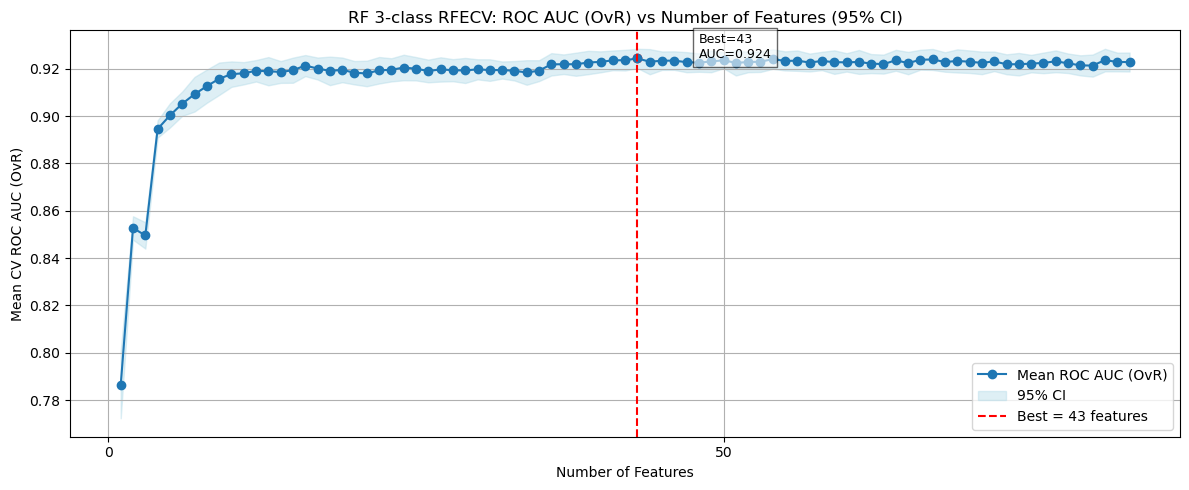

Best Parameters       : {'max_depth': None, 'n_estimators': 300}
Best CV ROC AUC (OvR) : 0.924
Train ROC AUC         : 1.000

Calibrated prob range per class:
  GOF: [0.007, 0.962]
  LOF: [0.000, 0.978]
  Neutral: [0.000, 0.993]


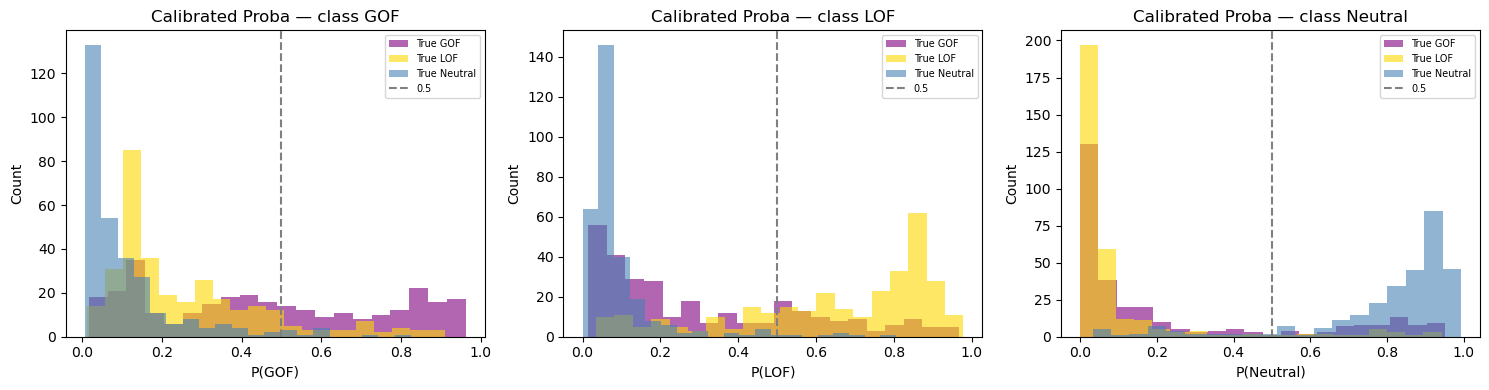


--- Test Set: Default (argmax) prediction ---


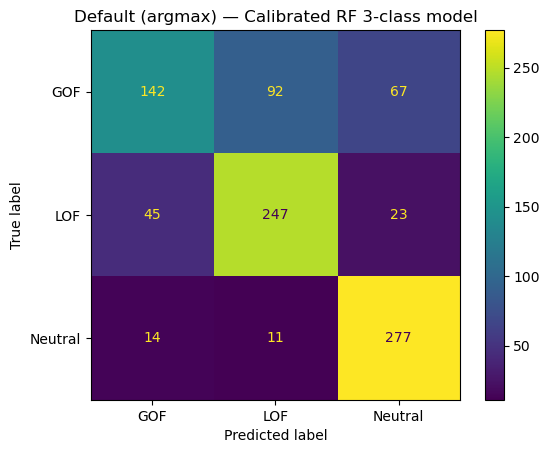

              precision    recall  f1-score   support

         GOF       0.71      0.47      0.57       301
         LOF       0.71      0.78      0.74       315
     Neutral       0.75      0.92      0.83       302

    accuracy                           0.73       918
   macro avg       0.72      0.72      0.71       918
weighted avg       0.72      0.73      0.71       918



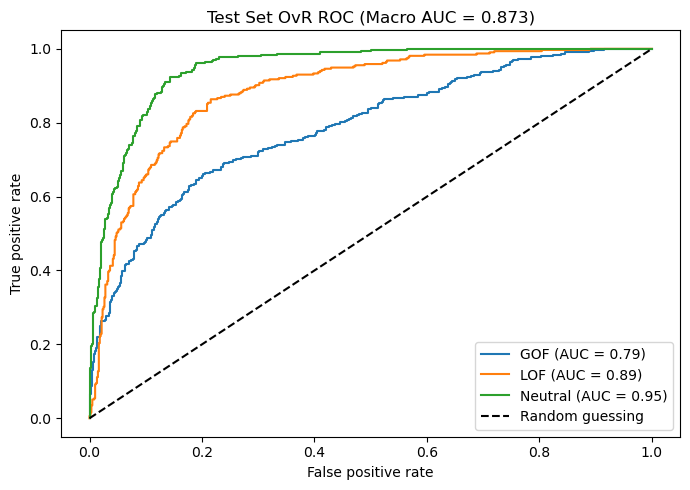


★ Test Set Macro OvR AUC (calibrated): 0.8730

★ RF Validation Macro OvR AUC (calibrated): 0.7952


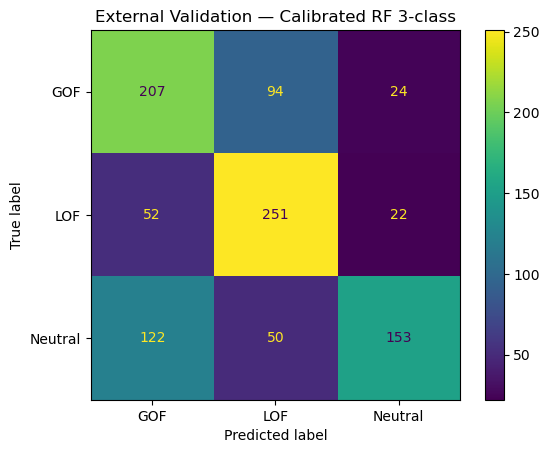

              precision    recall  f1-score   support

         GOF       0.54      0.64      0.59       325
         LOF       0.64      0.77      0.70       325
     Neutral       0.77      0.47      0.58       325

    accuracy                           0.63       975
   macro avg       0.65      0.63      0.62       975
weighted avg       0.65      0.63      0.62       975



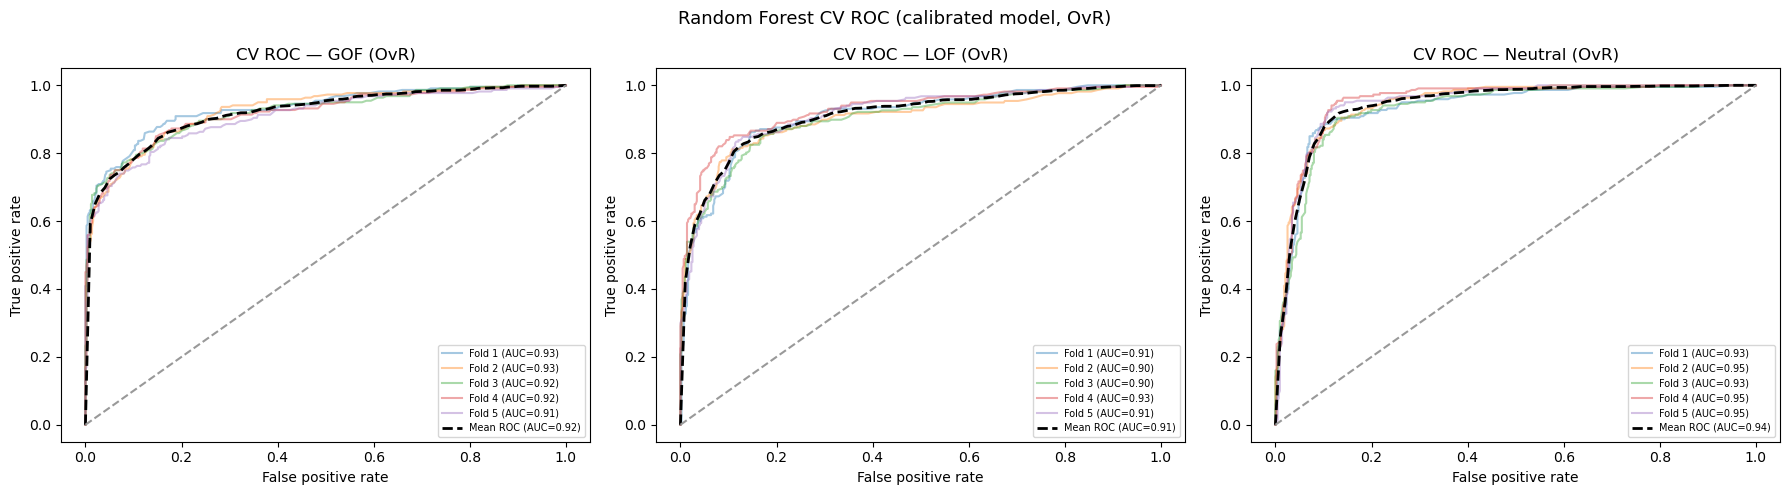


CV Macro OvR AUC: 0.924 ± 0.005
cv ROC AUC (OvR) : 0.922 ± 0.007
cv precision     : 0.805 ± 0.007
cv recall        : 0.804 ± 0.005
cv f1            : 0.803 ± 0.005


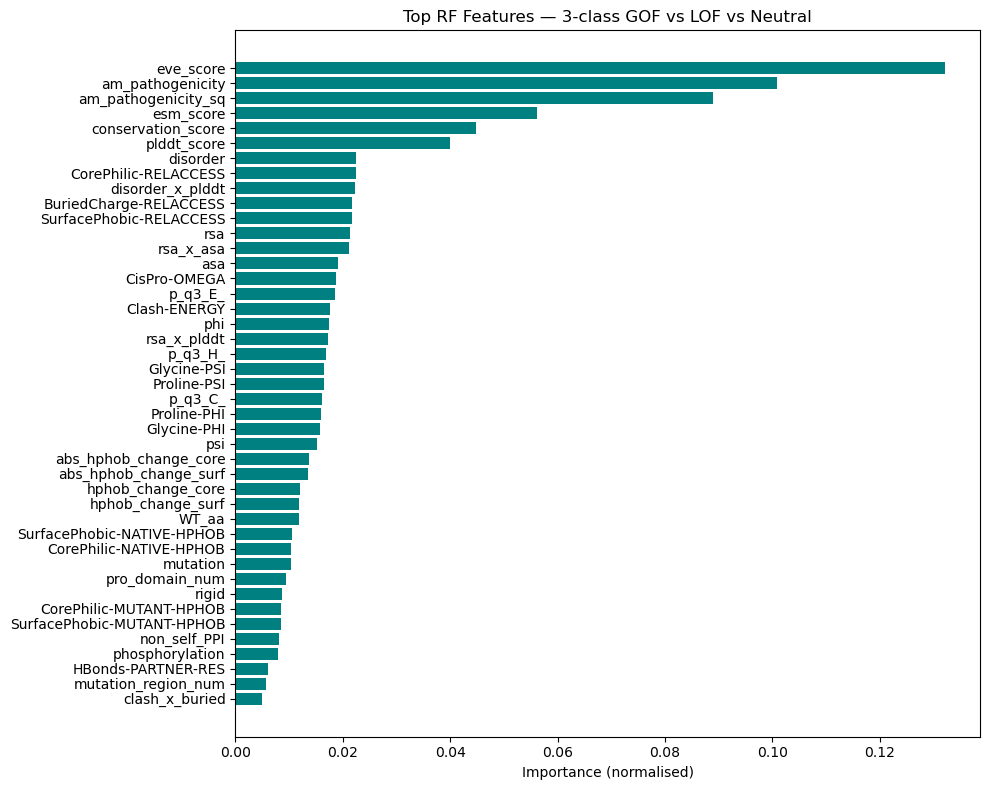


Top 10 features:
               Feature  Importance
             eve_score    0.132076
      am_pathogenicity    0.100837
   am_pathogenicity_sq    0.088971
             esm_score    0.056237
    conservation_score    0.044758
           plddt_score    0.039898
              disorder    0.022486
  CorePhilic-RELACCESS    0.022450
      disorder_x_plddt    0.022262
BuriedCharge-RELACCESS    0.021787


['calibrated_rf_3class_model.pkl']

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_selection import RFECV
from sklearn.metrics import (f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc,
                             make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import label_binarize

AUC, AUC_sd, AC, AC_sd, Pre, Pre_sd, Re, Re_sd, f1, f1_sd, Best1, Best2 = ([] for _ in range(12))

CLASSES      = ['GOF', 'LOF', 'Neutral']
CLASS_VALUES = [0, 1, 2]


# ── 2. RFECV Feature Selection ────────────────────────────────────────────────
print("Running RFECV for feature selection...")
rf_rfe    = RandomForestClassifier(n_estimators=300, random_state=42)
rfecv_rf  = RFECV(
    estimator=rf_rfe,
    step=1,
    min_features_to_select=1,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc_ovr",           # ← multiclass OvR
    n_jobs=-1,
)
rfecv_rf.fit(X_train, Y_train)

rf_features      = list(rfecv_rf.get_feature_names_out())
X_train_selected = X_train[rf_features]
X_test_selected  = X_test[rf_features]
print(f"RF optimal features: {rfecv_rf.n_features_} → {rf_features}")

# Plot RFECV curve with 95% CI
n_features  = len(rfecv_rf.cv_results_["mean_test_score"])
mean_scores = rfecv_rf.cv_results_["mean_test_score"]
std_scores  = rfecv_rf.cv_results_["std_test_score"]
ci          = 1.96 * (std_scores / np.sqrt(5))
x_range     = range(1, n_features + 1)
best_idx    = np.argmax(mean_scores)

plt.figure(figsize=(12, 5))
plt.plot(x_range, mean_scores, marker='o', label='Mean ROC AUC (OvR)')
plt.fill_between(x_range, mean_scores - ci, mean_scores + ci,
                 color='lightblue', alpha=0.4, label='95% CI')
plt.axvline(best_idx + 1, color='red', linestyle='--',
            label=f'Best = {best_idx + 1} features')
plt.scatter(best_idx + 1, mean_scores[best_idx], color='red')
plt.text(best_idx + 1 + 5, mean_scores[best_idx],
         f'Best={best_idx+1}\nAUC={mean_scores[best_idx]:.3f}',
         fontsize=9, bbox=dict(facecolor='white', alpha=0.6))
plt.xlabel("Number of Features"); plt.ylabel("Mean CV ROC AUC (OvR)")
plt.title("RF 3-class RFECV: ROC AUC (OvR) vs Number of Features (95% CI)")
plt.xticks(np.arange(0, n_features + 1, step=50))
plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig("RF_3class_RFECV_feature_selection.png", dpi=600)
plt.show()

# ── 3. GridSearchCV ───────────────────────────────────────────────────────────
param_grid = {
    'n_estimators': [10, 20, 30, 50, 100, 200, 300],
    'max_depth':    [1, 2, 3, 10, None]
}
gs = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring='roc_auc_ovr',
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    refit=True, n_jobs=-1, return_train_score=True
)
gs.fit(X_train_selected, Y_train)

best_params = gs.best_params_
print(f"Best Parameters       : {best_params}")
print(f"Best CV ROC AUC (OvR) : {gs.best_score_:.3f}")
print(f"Train ROC AUC         : {gs.cv_results_['mean_train_score'][gs.best_index_]:.3f}")

# ── 4. Calibrate probabilities ────────────────────────────────────────────────
raw_model        = RandomForestClassifier(**best_params, random_state=42)
calibrated_model_rf = CalibratedClassifierCV(raw_model, method='isotonic', cv=5)
calibrated_model_rf.fit(X_train_selected, Y_train)

proba_test_cal = calibrated_model_rf.predict_proba(X_test_selected)   # shape (n, 3)
print(f"\nCalibrated prob range per class:")
for i, cls in enumerate(CLASSES):
    print(f"  {cls}: [{proba_test_cal[:, i].min():.3f}, {proba_test_cal[:, i].max():.3f}]")

# ── 5. Probability distribution plot per class ────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors_cls = {0: 'purple', 1: 'gold', 2: 'steelblue'}
for i, (cls, ax) in enumerate(zip(CLASSES, axes)):
    for j, (label_name, color) in enumerate(zip(CLASSES, colors_cls.values())):
        ax.hist(proba_test_cal[Y_test == j, i], bins=20, alpha=0.6,
                label=f'True {label_name}', color=color)
    ax.axvline(0.5, color='gray', linestyle='--', label='0.5')
    ax.set_xlabel(f'P({cls})'); ax.set_ylabel('Count')
    ax.set_title(f'Calibrated Proba — class {cls}')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig("RF_3class_calibrated_proba_dist.png", dpi=600)
plt.show()

# ── 6. Test set: Default (argmax) prediction ──────────────────────────────────
print("\n--- Test Set: Default (argmax) prediction ---")
y_pred_default = np.argmax(proba_test_cal, axis=1)
cm_def = confusion_matrix(Y_test, y_pred_default, labels=CLASS_VALUES)
ConfusionMatrixDisplay(cm_def, display_labels=CLASSES).plot(cmap='viridis')
plt.title("Default (argmax) — Calibrated RF 3-class model")
plt.savefig("RF_3class_ConfusionMatrix_default_miRNA_HG.png", dpi=600)
plt.savefig("RF_3class_ConfusionMatrix_default_miRNA_HG.svg", dpi=600)
plt.show()
print(classification_report(Y_test, y_pred_default, target_names=CLASSES))

# ── 7. Multiclass ROC curves (One-vs-Rest) on TEST set ───────────────────────
y_test_bin = label_binarize(Y_test, classes=CLASS_VALUES)

plt.figure(figsize=(7, 5))
for i, cls in enumerate(CLASSES):
    fpr_i, tpr_i, _ = roc_curve(y_test_bin[:, i], proba_test_cal[:, i])
    auc_i = auc(fpr_i, tpr_i)
    plt.plot(fpr_i, tpr_i, label=f'{cls} (AUC = {auc_i:.2f})')

macro_auc_test = roc_auc_score(Y_test, proba_test_cal, multi_class='ovr', average='macro')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title(f'Test Set OvR ROC (Macro AUC = {macro_auc_test:.3f})')
plt.legend(loc='lower right'); plt.tight_layout()
plt.savefig("RF_3class_TestSet_ROC_miRNA_HG.png", dpi=600)
plt.show()
print(f"\n★ Test Set Macro OvR AUC (calibrated): {macro_auc_test:.4f}")

# ── 8. External Validation (BLIND) ────────────────────────────────────────────
rf_val_fresh = test_val_df.copy()
rf_val_fresh = clean_cols(rf_val_fresh)  # Ensure the validation data is cleaned
target_val    = rf_val_fresh['goflof']
X_val_rf      = rf_val_fresh[rf_features]
proba_val_cal = calibrated_model_rf.predict_proba(X_val_rf)

auc_val_macro = roc_auc_score(target_val, proba_val_cal, multi_class='ovr', average='macro')
print(f"\n★ RF Validation Macro OvR AUC (calibrated): {auc_val_macro:.4f}")

y_pred_val = np.argmax(proba_val_cal, axis=1)
cm_val = confusion_matrix(target_val, y_pred_val, labels=CLASS_VALUES)
ConfusionMatrixDisplay(cm_val, display_labels=CLASSES).plot(cmap='viridis')
plt.title("External Validation — Calibrated RF 3-class")
plt.savefig("RF_3class_ConfusionMatrix_validation.png", dpi=600)
plt.savefig("RF_3class_ConfusionMatrix_validation.svg", dpi=600)
plt.show()
print(classification_report(target_val, y_pred_val, target_names=CLASSES))

# ── 9. CV ROC folds (macro OvR per fold) ─────────────────────────────────────
cv_outer = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train_selected, Y_train))
mean_tpr = {cls: np.zeros(100) for cls in CLASSES}
mean_fpr = np.linspace(0, 1, 100)
sd_list  = []

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (tr, te) in enumerate(cv_outer):
    fold_model = RandomForestClassifier(**best_params, random_state=42)
    fold_model.fit(X_train_selected.iloc[tr], Y_train.iloc[tr])
    probas_fold = fold_model.predict_proba(X_train_selected.iloc[te])
    y_te_bin    = label_binarize(Y_train.iloc[te], classes=CLASS_VALUES)

    fold_aucs = []
    for j, (cls, ax) in enumerate(zip(CLASSES, axes)):
        fpr_j, tpr_j, _ = roc_curve(y_te_bin[:, j], probas_fold[:, j])
        fold_auc_j = auc(fpr_j, tpr_j)
        fold_aucs.append(fold_auc_j)
        mean_tpr[cls] += np.interp(mean_fpr, fpr_j, tpr_j)
        ax.plot(fpr_j, tpr_j, alpha=0.4, label=f'Fold {i+1} (AUC={fold_auc_j:.2f})')
    sd_list.append(np.mean(fold_aucs))

for j, (cls, ax) in enumerate(zip(CLASSES, axes)):
    mean_tpr[cls] /= len(cv_outer)
    mean_tpr[cls][0] = 0.0; mean_tpr[cls][-1] = 1.0
    mean_auc_cls = auc(mean_fpr, mean_tpr[cls])
    ax.plot(mean_fpr, mean_tpr[cls], 'k--', lw=2,
            label=f'Mean ROC (AUC={mean_auc_cls:.2f})')
    ax.plot([0, 1], [0, 1], linestyle='--', color=(.6, .6, .6))
    ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
    ax.set_title(f'CV ROC — {cls} (OvR)'); ax.legend(loc='lower right', fontsize=7)

plt.suptitle('Random Forest CV ROC (calibrated model, OvR)', fontsize=13)
plt.tight_layout()
plt.savefig("RF_3class_AUC_miRNA_HG.png", dpi=600)
plt.savefig("RF_3class_AUC_miRNA_HG.svg", dpi=600)
plt.show()

mean_auc = np.mean(sd_list); mean_sd = np.std(sd_list)
print(f"\nCV Macro OvR AUC: {mean_auc:.3f} ± {mean_sd:.3f}")
AUC.append(mean_auc); AUC_sd.append(mean_sd)

# ── 10. CV metrics ────────────────────────────────────────────────────────────
fresh_rf = RandomForestClassifier(**best_params, random_state=42)
scores1  = cross_val_score(fresh_rf, X_train_selected, Y_train, scoring='roc_auc_ovr', cv=5)
scores2  = cross_val_score(fresh_rf, X_train_selected, Y_train,
                           scoring=make_scorer(precision_score, average='macro'), cv=5)
scores3  = cross_val_score(fresh_rf, X_train_selected, Y_train,
                           scoring=make_scorer(recall_score,    average='macro'), cv=5)
scores4  = cross_val_score(fresh_rf, X_train_selected, Y_train,
                           scoring=make_scorer(f1_score,        average='macro'), cv=5)

print(f"cv ROC AUC (OvR) : {np.mean(scores1):.3f} ± {np.std(scores1):.3f}")
print(f"cv precision     : {np.mean(scores2):.3f} ± {np.std(scores2):.3f}")
print(f"cv recall        : {np.mean(scores3):.3f} ± {np.std(scores3):.3f}")
print(f"cv f1            : {np.mean(scores4):.3f} ± {np.std(scores4):.3f}")

AC.append(np.mean(scores1));  AC_sd.append(np.std(scores1))
Pre.append(np.mean(scores2)); Pre_sd.append(np.std(scores2))
Re.append(np.mean(scores3));  Re_sd.append(np.std(scores3))
f1.append(np.mean(scores4));  f1_sd.append(np.std(scores4))
Best1.append(best_params['n_estimators'])
Best2.append(best_params['max_depth'])

# ── 11. Feature importance ────────────────────────────────────────────────────
importances_list = [clf.estimator.feature_importances_
                    for clf in calibrated_model_rf.calibrated_classifiers_]
importances = np.mean(importances_list, axis=0)
importances = importances / importances.sum()

feature_importance_df = pd.DataFrame({'Feature': X_train_selected.columns,
                                       'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

n_top = min(52, len(feature_importance_df))
plt.figure(figsize=(10, 8))
plt.barh(feature_importance_df['Feature'][:n_top][::-1],
         feature_importance_df['Importance'][:n_top][::-1], color='teal')
plt.xlabel('Importance (normalised)')
plt.title('Top RF Features — 3-class GOF vs LOF vs Neutral')
plt.tight_layout()
plt.savefig("RF_3class_FeatureImportance_miRNA_HG.png", dpi=600)
plt.show()
print("\nTop 10 features:")
print(feature_importance_df.head(10).to_string(index=False))
# ___ 12. Save the model for future use
import joblib
model_filename = "calibrated_rf_3class_model.pkl"
joblib.dump(calibrated_model_rf, model_filename)


2. XGB

Running RFECV for feature selection...
XGB optimal features: 29 → ['WT_aa', 'BuriedCharge-RELACCESS', 'BuriedCharge-NATIVE-CHARGE', 'CisPro-BOOL', 'CorePhilic-NATIVE-HPHOB', 'CorePhilic-BOOL', 'Glycine-PSI', 'HBonds-PARTNER-RES', 'Proline-NATIVE-ENERGY', 'SSGeom-BOOL', 'plddt_score', 'asa', 'p_q3_H_', 'p_q3_E_', 'disorder', 'am_pathogenicity', 'phosphorylation', 'ubiquitination', 'pro_domain_num', 'mutation_region_num', 'self_PPI', 'non_self_PPI', 'conservation_score', 'esm_score', 'eve_score', 'abs_charge_change', 'disorder_x_plddt', 'clash_x_buried', 'hbonds_x_buried']


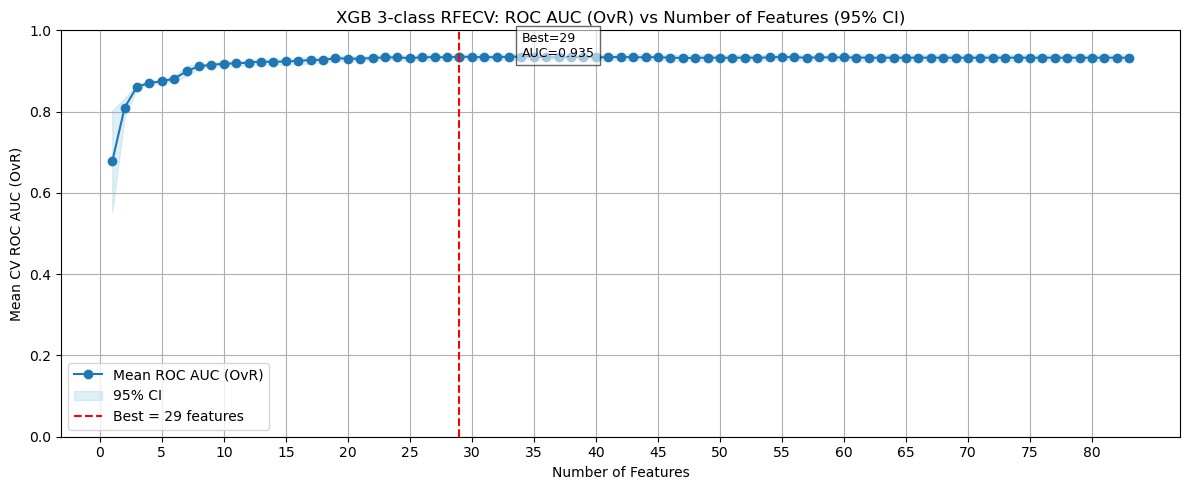

/opt/anaconda3/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best Parameters       : {'learning_rate': 0.1, 'max_depth': 9, 'n_estimators': 200}
Best CV ROC AUC (OvR) : 0.937
Train ROC AUC         : 1.000

Calibrated prob range per class:
  GOF: [0.001, 1.000]
  LOF: [0.000, 0.991]
  Neutral: [0.000, 0.993]


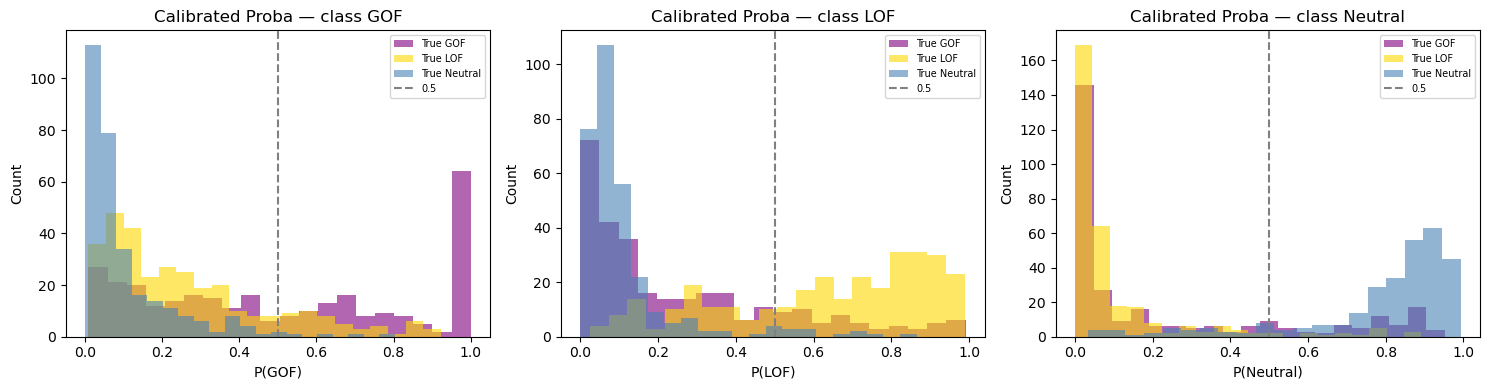


--- Test Set: Default (argmax) prediction ---


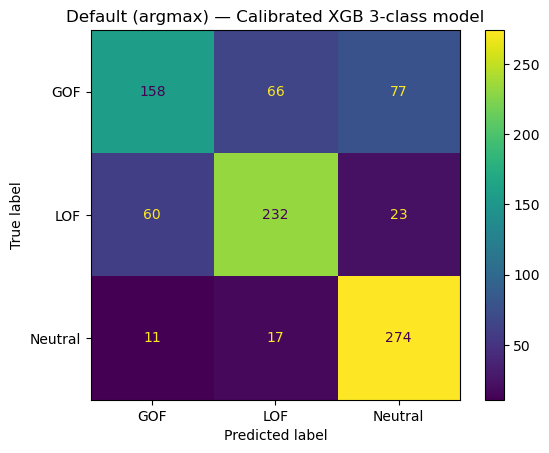

              precision    recall  f1-score   support

         GOF       0.69      0.52      0.60       301
         LOF       0.74      0.74      0.74       315
     Neutral       0.73      0.91      0.81       302

    accuracy                           0.72       918
   macro avg       0.72      0.72      0.71       918
weighted avg       0.72      0.72      0.71       918



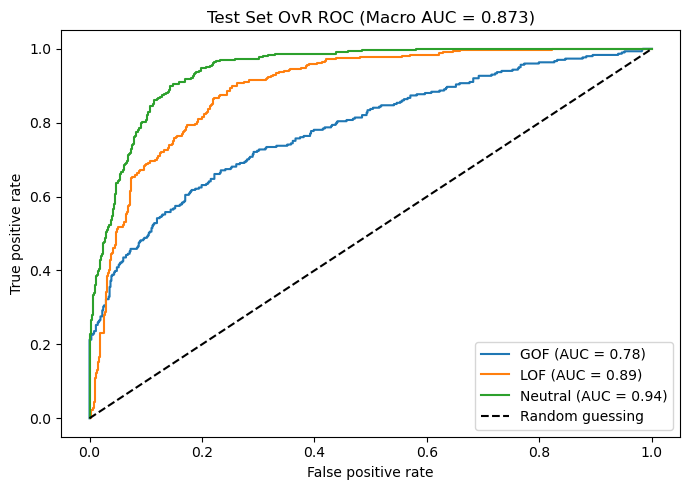


★ Test Set Macro OvR AUC (calibrated): 0.8733

★ XGB Validation Macro OvR AUC (calibrated): 0.7732


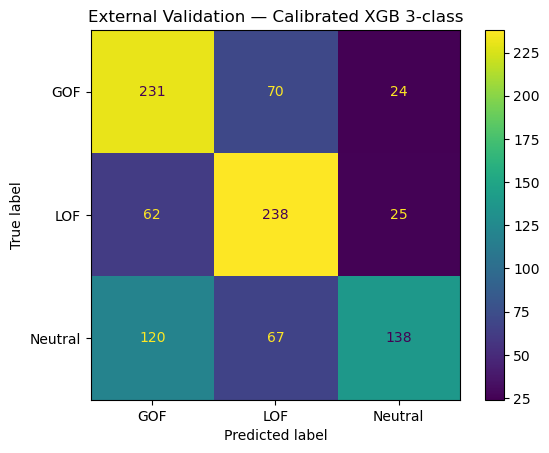

              precision    recall  f1-score   support

         GOF       0.56      0.71      0.63       325
         LOF       0.63      0.73      0.68       325
     Neutral       0.74      0.42      0.54       325

    accuracy                           0.62       975
   macro avg       0.64      0.62      0.62       975
weighted avg       0.64      0.62      0.62       975



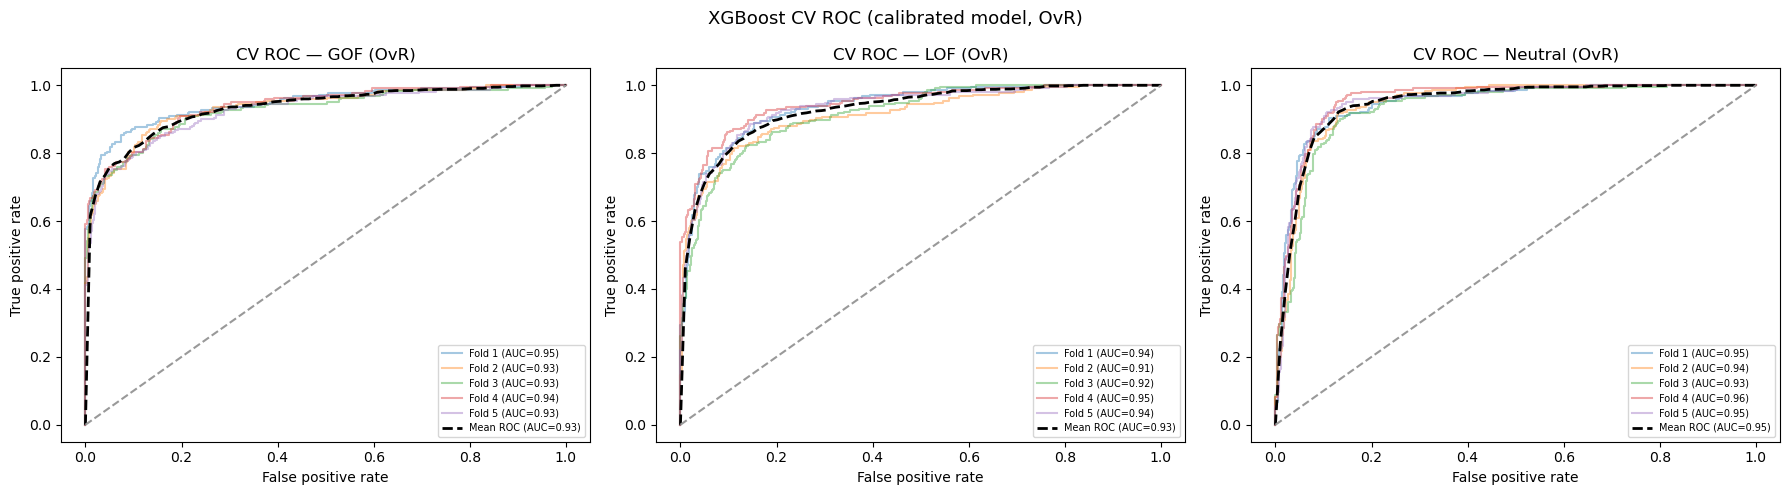


CV Macro OvR AUC: 0.937 ± 0.008
cv ROC AUC (OvR) : 0.936 ± 0.005
cv precision     : 0.823 ± 0.014
cv recall        : 0.821 ± 0.012
cv f1            : 0.821 ± 0.012


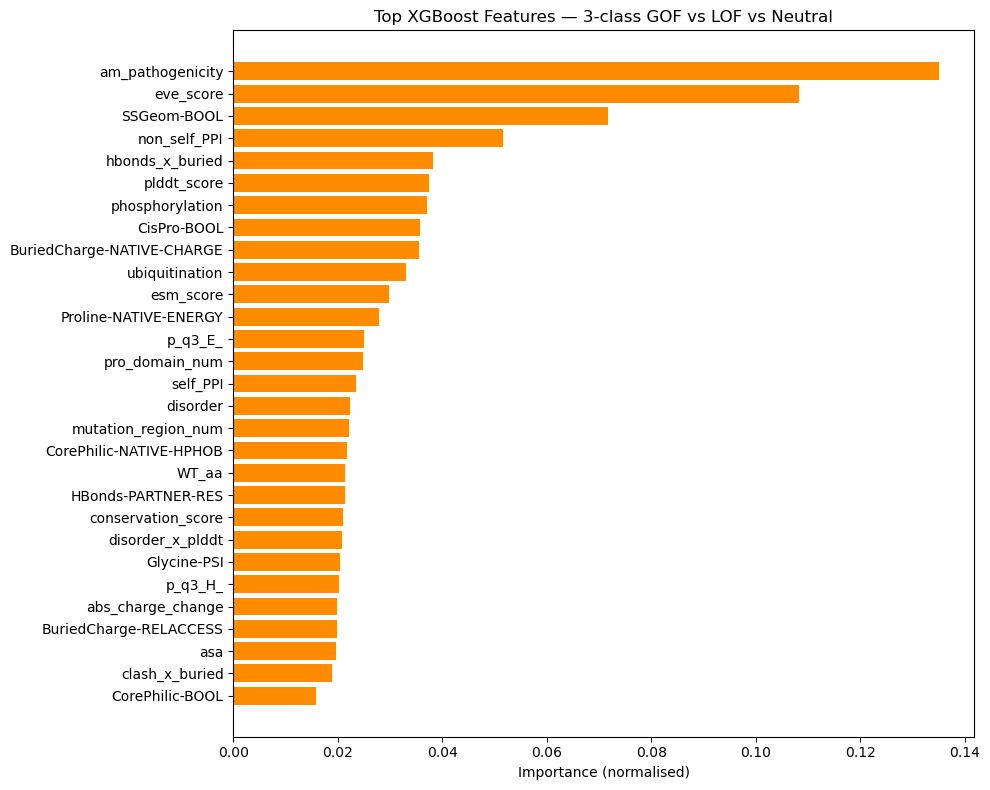


Top 10 features:
                   Feature  Importance
          am_pathogenicity    0.135057
                 eve_score    0.108264
               SSGeom-BOOL    0.071727
              non_self_PPI    0.051693
           hbonds_x_buried    0.038293
               plddt_score    0.037364
           phosphorylation    0.037008
               CisPro-BOOL    0.035745
BuriedCharge-NATIVE-CHARGE    0.035446
            ubiquitination    0.033075


['calibrated_xgb_3class_model.pkl']

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import xgboost as xgb
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_selection import RFECV
from sklearn.metrics import (f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc,
                             make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import label_binarize

AUC, AUC_sd, AC, AC_sd, Pre, Pre_sd, Re, Re_sd, f1, f1_sd, Best1, Best2 = ([] for _ in range(12))

CLASSES      = ['GOF', 'LOF', 'Neutral']
CLASS_VALUES = [0, 1, 2]



# ── 2. RFECV Feature Selection ────────────────────────────────────────────────
print("Running RFECV for feature selection...")
xgb_rfe   = xgb.XGBClassifier(
    n_estimators=100, eval_metric='mlogloss',
    objective='multi:softprob', num_class=3,
    random_state=42, verbosity=0
)
rfecv_xgb = RFECV(
    estimator=xgb_rfe,
    step=1,
    min_features_to_select=1,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc_ovr",           # ← multiclass OvR
    n_jobs=-1,
)
rfecv_xgb.fit(X_train, Y_train)

xgb_features     = list(rfecv_xgb.get_feature_names_out())
X_train_selected = X_train[xgb_features]
X_test_selected  = X_test[xgb_features]
print(f"XGB optimal features: {rfecv_xgb.n_features_} → {xgb_features}")

# Plot RFECV curve with 95% CI
n_features  = len(rfecv_xgb.cv_results_["mean_test_score"])
mean_scores = rfecv_xgb.cv_results_["mean_test_score"]
std_scores  = rfecv_xgb.cv_results_["std_test_score"]
ci          = 1.96 * (std_scores / np.sqrt(5))
x_range     = range(1, n_features + 1)
best_idx    = np.argmax(mean_scores)

plt.figure(figsize=(12, 5))
plt.plot(x_range, mean_scores, marker='o', label='Mean ROC AUC (OvR)')
plt.fill_between(x_range, mean_scores - ci, mean_scores + ci,
                 color='lightblue', alpha=0.4, label='95% CI')
plt.axvline(best_idx + 1, color='red', linestyle='--',
            label=f'Best = {best_idx + 1} features')
plt.scatter(best_idx + 1, mean_scores[best_idx], color='red')
plt.text(best_idx + 1 + 5, mean_scores[best_idx],
         f'Best={best_idx+1}\nAUC={mean_scores[best_idx]:.3f}',
         fontsize=9, bbox=dict(facecolor='white', alpha=0.6))
plt.xlabel("Number of Features"); plt.ylabel("Mean CV ROC AUC (OvR)")
plt.title("XGB 3-class RFECV: ROC AUC (OvR) vs Number of Features (95% CI)")
plt.xticks(np.arange(0, n_features + 1, step=5))
plt.ylim(0, 1.0)
plt.grid(True); plt.legend(); plt.tight_layout()
plt.savefig("XGB_3class_RFECV_feature_selection.png", dpi=600)
plt.show()

# ── 3. GridSearchCV ───────────────────────────────────────────────────────────
param_grid = {
    'n_estimators':  [10, 20, 30, 50, 100, 200, 300, 350, 400],
    'max_depth':     [1, 3, 5, 7, 9, 15],
    'learning_rate': [0.01, 0.1, 0.2, 0.21]
}
gs = GridSearchCV(
    estimator=xgb.XGBClassifier(
        eval_metric='mlogloss', objective='multi:softprob',
        num_class=3, random_state=42, verbosity=0
    ),
    param_grid=param_grid,
    scoring='roc_auc_ovr',
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    refit=True, n_jobs=-1, return_train_score=True
)
gs.fit(X_train_selected, Y_train)

best_params = gs.best_params_
print(f"Best Parameters       : {best_params}")
print(f"Best CV ROC AUC (OvR) : {gs.best_score_:.3f}")
print(f"Train ROC AUC         : {gs.cv_results_['mean_train_score'][gs.best_index_]:.3f}")

# ── 4. Calibrate probabilities ────────────────────────────────────────────────
raw_model = xgb.XGBClassifier(
    **best_params, eval_metric='mlogloss',
    objective='multi:softprob', num_class=3,
    random_state=42, verbosity=0
)
calibrated_model_xgb = CalibratedClassifierCV(raw_model, method='isotonic', cv=5)
calibrated_model_xgb.fit(X_train_selected, Y_train)

proba_test_cal = calibrated_model_xgb.predict_proba(X_test_selected)   # shape (n, 3)
print(f"\nCalibrated prob range per class:")
for i, cls in enumerate(CLASSES):
    print(f"  {cls}: [{proba_test_cal[:, i].min():.3f}, {proba_test_cal[:, i].max():.3f}]")

# ── 5. Probability distribution plot per class ────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors_cls = {0: 'purple', 1: 'gold', 2: 'steelblue'}
for i, (cls, ax) in enumerate(zip(CLASSES, axes)):
    for j, (label_name, color) in enumerate(zip(CLASSES, colors_cls.values())):
        ax.hist(proba_test_cal[Y_test == j, i], bins=20, alpha=0.6,
                label=f'True {label_name}', color=color)
    ax.axvline(0.5, color='gray', linestyle='--', label='0.5')
    ax.set_xlabel(f'P({cls})'); ax.set_ylabel('Count')
    ax.set_title(f'Calibrated Proba — class {cls}')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig("xgb_3class_calibrated_proba_dist.png", dpi=600)
plt.show()

# ── 6. Test set: Default (argmax) prediction ──────────────────────────────────
print("\n--- Test Set: Default (argmax) prediction ---")
y_pred_default = np.argmax(proba_test_cal, axis=1)
cm_def = confusion_matrix(Y_test, y_pred_default, labels=CLASS_VALUES)
ConfusionMatrixDisplay(cm_def, display_labels=CLASSES).plot(cmap='viridis')
plt.title("Default (argmax) — Calibrated XGB 3-class model")
plt.savefig("xgb_3class_ConfusionMatrix_default_miRNA_HG.png", dpi=600)
plt.savefig("xgb_3class_ConfusionMatrix_default_miRNA_HG.svg", dpi=600)
plt.show()
print(classification_report(Y_test, y_pred_default, target_names=CLASSES))

# ── 7. Multiclass ROC curves (One-vs-Rest) on TEST set ───────────────────────
Y_test_bin = label_binarize(Y_test, classes=CLASS_VALUES)

plt.figure(figsize=(7, 5))
for i, cls in enumerate(CLASSES):
    fpr_i, tpr_i, _ = roc_curve(Y_test_bin[:, i], proba_test_cal[:, i])
    auc_i = auc(fpr_i, tpr_i)
    plt.plot(fpr_i, tpr_i, label=f'{cls} (AUC = {auc_i:.2f})')

macro_auc_test = roc_auc_score(Y_test, proba_test_cal, multi_class='ovr', average='macro')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title(f'Test Set OvR ROC (Macro AUC = {macro_auc_test:.3f})')
plt.legend(loc='lower right'); plt.tight_layout()
plt.savefig("xgb_3class_TestSet_ROC_miRNA_HG.png", dpi=600)
plt.show()
print(f"\n★ Test Set Macro OvR AUC (calibrated): {macro_auc_test:.4f}")

# ── 8. External Validation (BLIND) ────────────────────────────────────────────
xgb_val_fresh = test_val_df.copy()
target_val    = xgb_val_fresh['goflof']
xgb_val_fresh = clean_cols(xgb_val_fresh)  # Ensure the validation data is cleaned
X_val_xgb     = xgb_val_fresh[xgb_features]
proba_val_cal = calibrated_model_xgb.predict_proba(X_val_xgb)

auc_val_macro = roc_auc_score(target_val, proba_val_cal, multi_class='ovr', average='macro')
print(f"\n★ XGB Validation Macro OvR AUC (calibrated): {auc_val_macro:.4f}")

y_pred_val = np.argmax(proba_val_cal, axis=1)
cm_val = confusion_matrix(target_val, y_pred_val, labels=CLASS_VALUES)
ConfusionMatrixDisplay(cm_val, display_labels=CLASSES).plot(cmap='viridis')
plt.title("External Validation — Calibrated XGB 3-class")
plt.savefig("xgb_3class_ConfusionMatrix_validation.png", dpi=600)
plt.savefig("xgb_3class_ConfusionMatrix_validation.svg", dpi=600)
plt.show()
print(classification_report(target_val, y_pred_val, target_names=CLASSES))

# ── 9. CV ROC folds (macro OvR per fold) ─────────────────────────────────────
cv_outer = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train_selected, Y_train))
mean_tpr = {cls: np.zeros(100) for cls in CLASSES}
mean_fpr = np.linspace(0, 1, 100)
sd_list  = []

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (tr, te) in enumerate(cv_outer):
    fold_model = xgb.XGBClassifier(
        **best_params, eval_metric='mlogloss',
        objective='multi:softprob', num_class=3,
        random_state=42, verbosity=0
    )
    fold_model.fit(X_train_selected.iloc[tr], Y_train.iloc[tr])
    probas_fold = fold_model.predict_proba(X_train_selected.iloc[te])
    y_te_bin    = label_binarize(Y_train.iloc[te], classes=CLASS_VALUES)

    fold_aucs = []
    for j, (cls, ax) in enumerate(zip(CLASSES, axes)):
        fpr_j, tpr_j, _ = roc_curve(y_te_bin[:, j], probas_fold[:, j])
        fold_auc_j = auc(fpr_j, tpr_j)
        fold_aucs.append(fold_auc_j)
        mean_tpr[cls] += np.interp(mean_fpr, fpr_j, tpr_j)
        ax.plot(fpr_j, tpr_j, alpha=0.4, label=f'Fold {i+1} (AUC={fold_auc_j:.2f})')
    sd_list.append(np.mean(fold_aucs))

for j, (cls, ax) in enumerate(zip(CLASSES, axes)):
    mean_tpr[cls] /= len(cv_outer)
    mean_tpr[cls][0] = 0.0; mean_tpr[cls][-1] = 1.0
    mean_auc_cls = auc(mean_fpr, mean_tpr[cls])
    ax.plot(mean_fpr, mean_tpr[cls], 'k--', lw=2,
            label=f'Mean ROC (AUC={mean_auc_cls:.2f})')
    ax.plot([0, 1], [0, 1], linestyle='--', color=(.6, .6, .6))
    ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
    ax.set_title(f'CV ROC — {cls} (OvR)'); ax.legend(loc='lower right', fontsize=7)

plt.suptitle('XGBoost CV ROC (calibrated model, OvR)', fontsize=13)
plt.tight_layout()
plt.savefig("xgb_3class_AUC_miRNA_HG.png", dpi=600)
plt.savefig("xgb_3class_AUC_miRNA_HG.svg", dpi=600)
plt.show()

mean_auc = np.mean(sd_list); mean_sd = np.std(sd_list)
print(f"\nCV Macro OvR AUC: {mean_auc:.3f} ± {mean_sd:.3f}")
AUC.append(mean_auc); AUC_sd.append(mean_sd)

# ── 10. CV metrics ────────────────────────────────────────────────────────────
fresh_xgb = xgb.XGBClassifier(
    **best_params, eval_metric='mlogloss',
    objective='multi:softprob', num_class=3,
    random_state=42, verbosity=0
)
scores1 = cross_val_score(fresh_xgb, X_train_selected, Y_train, scoring='roc_auc_ovr', cv=5)
scores2 = cross_val_score(fresh_xgb, X_train_selected, Y_train,
                          scoring=make_scorer(precision_score, average='macro'), cv=5)
scores3 = cross_val_score(fresh_xgb, X_train_selected, Y_train,
                          scoring=make_scorer(recall_score,    average='macro'), cv=5)
scores4 = cross_val_score(fresh_xgb, X_train_selected, Y_train,
                          scoring=make_scorer(f1_score,        average='macro'), cv=5)

print(f"cv ROC AUC (OvR) : {np.mean(scores1):.3f} ± {np.std(scores1):.3f}")
print(f"cv precision     : {np.mean(scores2):.3f} ± {np.std(scores2):.3f}")
print(f"cv recall        : {np.mean(scores3):.3f} ± {np.std(scores3):.3f}")
print(f"cv f1            : {np.mean(scores4):.3f} ± {np.std(scores4):.3f}")

AC.append(np.mean(scores1));  AC_sd.append(np.std(scores1))
Pre.append(np.mean(scores2)); Pre_sd.append(np.std(scores2))
Re.append(np.mean(scores3));  Re_sd.append(np.std(scores3))
f1.append(np.mean(scores4));  f1_sd.append(np.std(scores4))
Best1.append(best_params['n_estimators'])
Best2.append(best_params['max_depth'])

# ── 11. Feature importance ────────────────────────────────────────────────────
importances_list = [clf.estimator.feature_importances_
                    for clf in calibrated_model_xgb.calibrated_classifiers_]
importances = np.mean(importances_list, axis=0)
importances = importances / importances.sum()

feature_importance_df = pd.DataFrame({'Feature': X_train_selected.columns,
                                       'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

n_top = min(52, len(feature_importance_df))
plt.figure(figsize=(10, 8))
plt.barh(feature_importance_df['Feature'][:n_top][::-1],
         feature_importance_df['Importance'][:n_top][::-1], color='darkorange')
plt.xlabel('Importance (normalised)')
plt.title('Top XGBoost Features — 3-class GOF vs LOF vs Neutral')
plt.tight_layout()
plt.savefig("xgb_3class_FeatureImportance_miRNA_HG.png", dpi=600)
plt.show()
print("\nTop 10 features:")
print(feature_importance_df.head(10).to_string(index=False))

# ___ 12. Save the model for future use
import joblib
model_filename = "calibrated_xgb_3class_model.pkl"
joblib.dump(calibrated_model_xgb, model_filename)


> 3. LGBM Model 

Running RFECV for feature selection...


/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/anaconda3/lib/python3.12/

LGB optimal features: 45 → ['mutation', 'WT_aa', 'BuriedCharge-RELACCESS', 'BuriedCharge-NATIVE-CHARGE', 'CisPro-OMEGA', 'Clash-ENERGY', 'CorePhilic-NATIVE-HPHOB', 'CorePhilic-MUTANT-HPHOB', 'Glycine-MUTANT-ENERGY', 'Glycine-PHI', 'Glycine-PSI', 'HBonds-ZVAL', 'HBonds-PARTNER-RES', 'HBonds-ENERGY', 'SSGeom-BOOL', 'plddt_score', 'rsa', 'asa', 'p_q3_H_', 'p_q3_E_', 'p_q3_C_', 'phi', 'psi', 'disorder', 'am_pathogenicity', 'phosphorylation', 'ubiquitination', 'sumoylation', 'pro_domain_num', 'mutation_region_num', 'self_PPI', 'non_self_PPI', 'conservation_score', 'esm_score', 'eve_score', 'charge_change', 'abs_charge_change', 'hphob_change_core', 'abs_hphob_change_core', 'glycine_energy_change', 'rsa_x_asa', 'rsa_x_plddt', 'disorder_x_plddt', 'clash_x_buried', 'hbonds_x_buried']


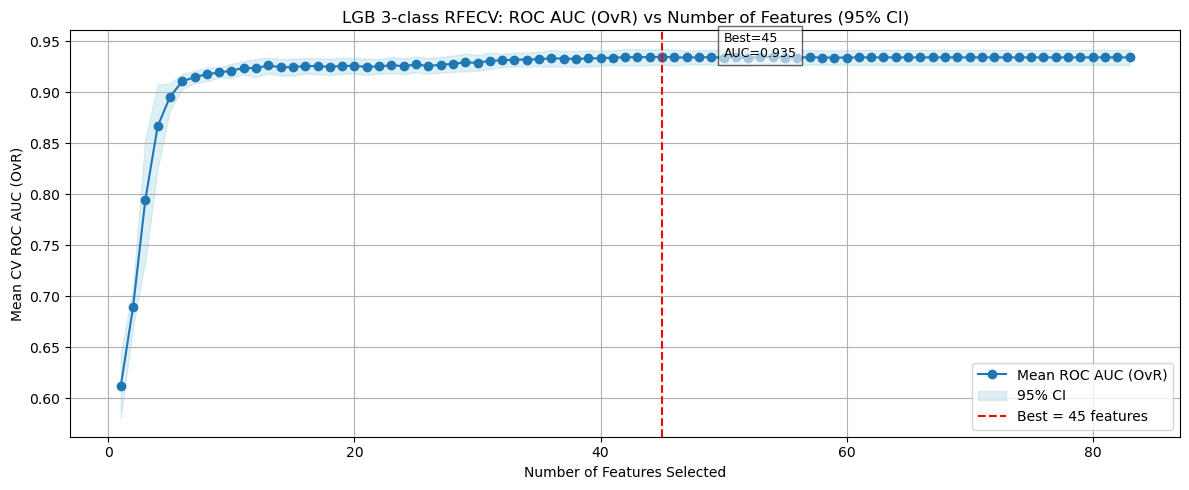

Fitting 5 folds for each of 128 candidates, totalling 640 fits
Best Parameters       : {'learning_rate': 0.2, 'max_depth': 5, 'min_child_samples': 10, 'n_estimators': 200, 'num_leaves': 31, 'reg_alpha': 0.1, 'reg_lambda': 0.1}
Best CV ROC AUC (OvR) : 0.934
Train ROC AUC         : 1.000

Calibrated prob range per class:
  GOF: [0.002, 1.000]
  LOF: [0.000, 0.994]
  Neutral: [0.000, 0.995]


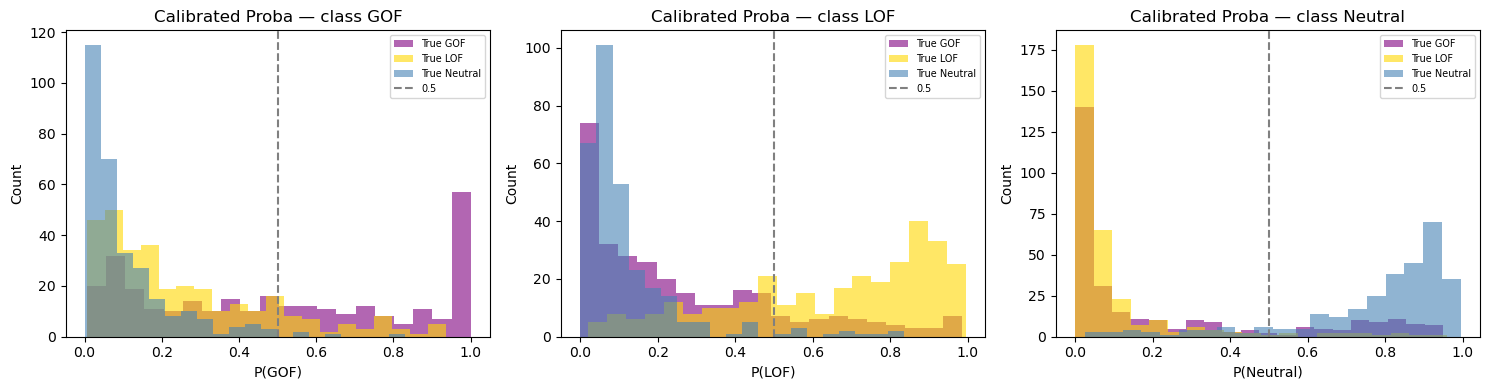


--- Test Set: Default (argmax) prediction ---


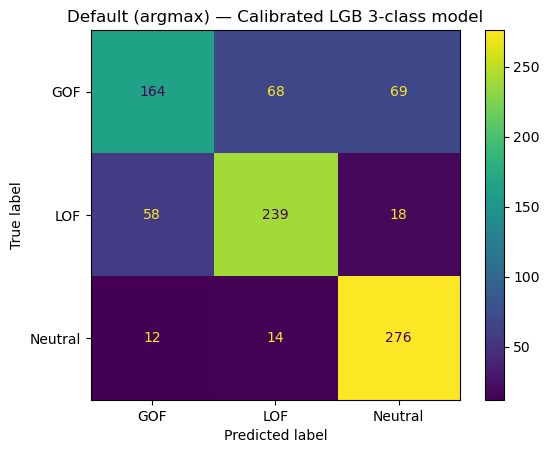

              precision    recall  f1-score   support

         GOF       0.70      0.54      0.61       301
         LOF       0.74      0.76      0.75       315
     Neutral       0.76      0.91      0.83       302

    accuracy                           0.74       918
   macro avg       0.74      0.74      0.73       918
weighted avg       0.74      0.74      0.73       918



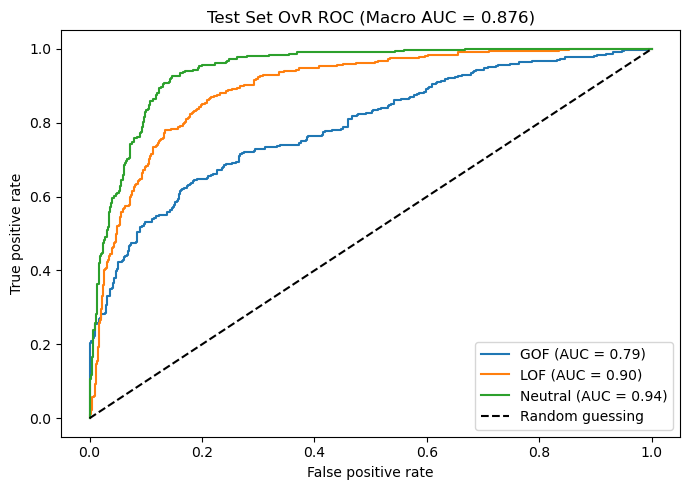


★ Test Set Macro OvR AUC (calibrated): 0.8759

★ LGB Validation Macro OvR AUC (calibrated): 0.7879


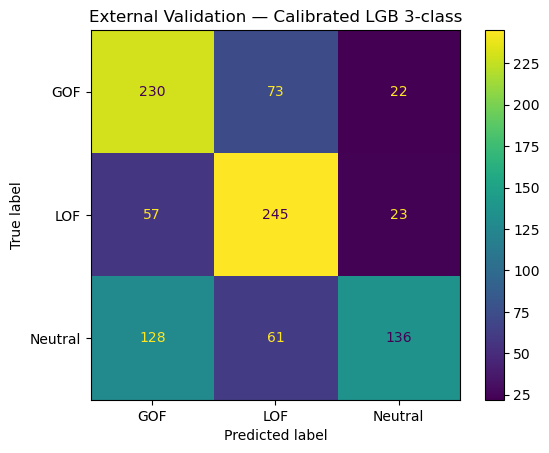

              precision    recall  f1-score   support

         GOF       0.55      0.71      0.62       325
         LOF       0.65      0.75      0.70       325
     Neutral       0.75      0.42      0.54       325

    accuracy                           0.63       975
   macro avg       0.65      0.63      0.62       975
weighted avg       0.65      0.63      0.62       975



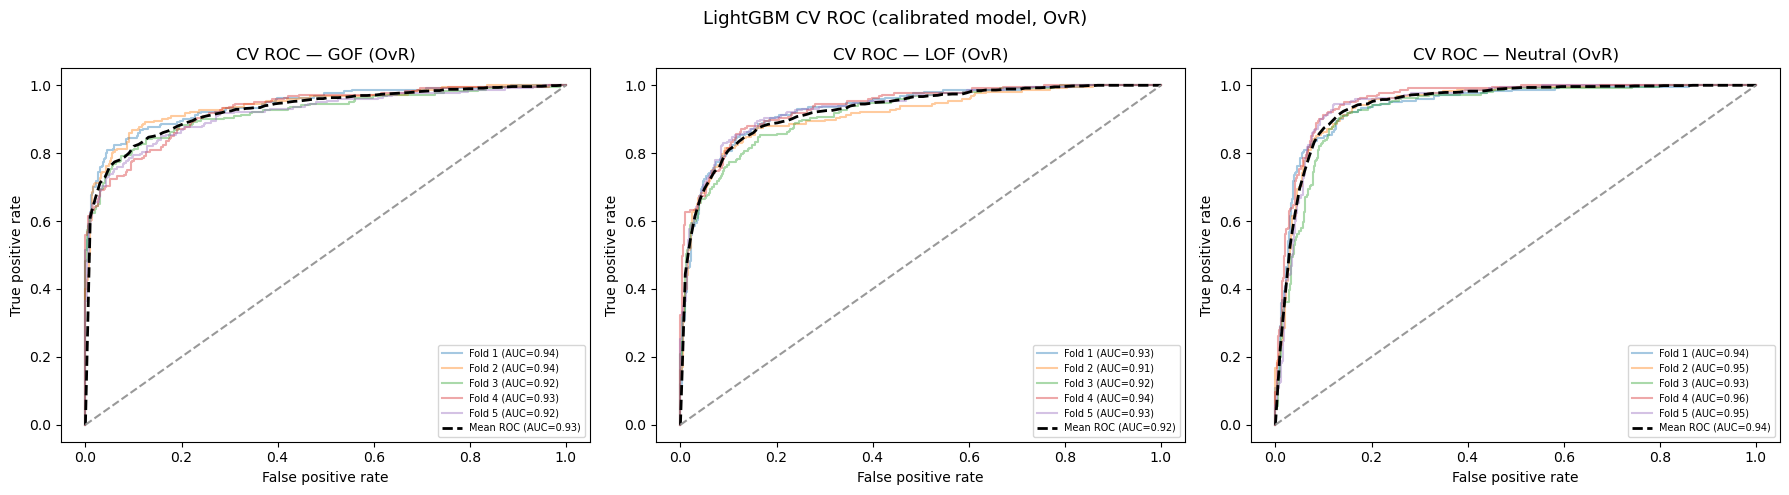


CV Macro OvR AUC: 0.934 ± 0.006
cv ROC AUC (OvR) : 0.933 ± 0.008
cv precision     : 0.817 ± 0.011
cv recall        : 0.815 ± 0.010
cv f1            : 0.814 ± 0.010


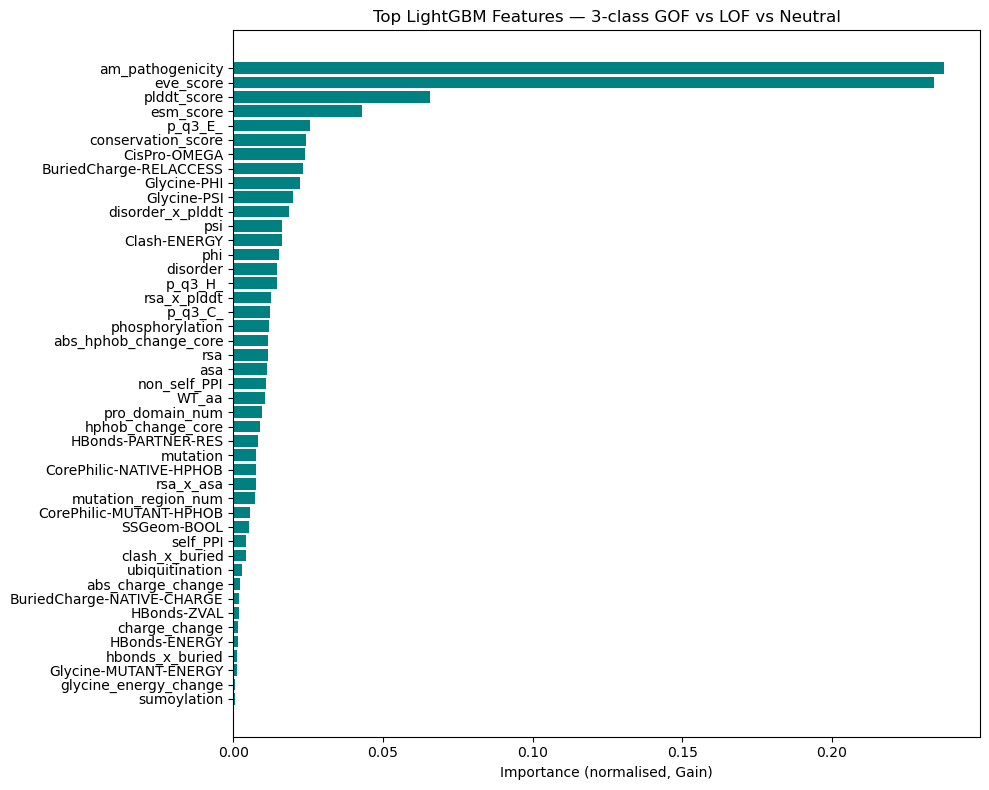


Top 10 features:
               Feature  Importance
      am_pathogenicity    0.237638
             eve_score    0.234197
           plddt_score    0.065680
             esm_score    0.042968
               p_q3_E_    0.025613
    conservation_score    0.024366
          CisPro-OMEGA    0.024080
BuriedCharge-RELACCESS    0.023297
           Glycine-PHI    0.022255
           Glycine-PSI    0.019811


['calibrated_lgb_3class_model.pkl']

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import lightgbm as lgb
from sklearn.calibration import CalibratedClassifierCV
from sklearn.feature_selection import RFECV
from sklearn.metrics import (f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc,
                             make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import label_binarize

AUC, AUC_sd, AC, AC_sd, Pre, Pre_sd, Re, Re_sd, f1, f1_sd, Best1, Best2 = ([] for _ in range(12))

CLASSES      = ['GOF', 'LOF', 'Neutral']
CLASS_VALUES = [0, 1, 2]


# ── 2. RFECV Feature Selection ────────────────────────────────────────────────
print("Running RFECV for feature selection...")
lgb_rfe   = lgb.LGBMClassifier(
    n_estimators=100, random_state=42, verbose=-1,
    class_weight='balanced', objective='multiclass', num_class=3
)
rfecv_lgb = RFECV(
    estimator=lgb_rfe,
    step=1,
    min_features_to_select=1,
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc_ovr",           # ← multiclass OvR
    n_jobs=-1,
)
rfecv_lgb.fit(X_train, Y_train)

lgb_features     = list(rfecv_lgb.get_feature_names_out())
X_train_selected = X_train[lgb_features]
X_test_selected  = X_test[lgb_features]
print(f"LGB optimal features: {rfecv_lgb.n_features_} → {lgb_features}")

# Plot RFECV curve with 95% CI
mean_scores = rfecv_lgb.cv_results_["mean_test_score"]
std_scores  = rfecv_lgb.cv_results_["std_test_score"]
n_steps     = len(mean_scores)

total_feats = X_train.shape[1]
step        = rfecv_lgb.step
min_feats   = rfecv_lgb.min_features_to_select

# feature count at each step, from many → few features
feature_counts = []
n = total_feats
for _ in range(n_steps):
    feature_counts.append(n)
    n = max(min_feats, n - step)

# If scores are stored from few→many instead, just reverse:
feature_counts = feature_counts[::-1]

ci       = 1.96 * (std_scores / np.sqrt(5))
best_idx = np.argmax(mean_scores)
best_n   = feature_counts[best_idx]

plt.figure(figsize=(12, 5))
plt.plot(feature_counts, mean_scores, marker='o', label='Mean ROC AUC (OvR)')
plt.fill_between(feature_counts, mean_scores - ci, mean_scores + ci,
                 color='lightblue', alpha=0.4, label='95% CI')
plt.axvline(best_n, color='red', linestyle='--',
            label=f'Best = {best_n} features')
plt.scatter(best_n, mean_scores[best_idx], color='red')
plt.text(best_n + 5, mean_scores[best_idx],
         f'Best={best_n}\nAUC={mean_scores[best_idx]:.3f}',
         fontsize=9, bbox=dict(facecolor='white', alpha=0.6))
plt.xlabel("Number of Features Selected")
plt.ylabel("Mean CV ROC AUC (OvR)")
plt.title("LGB 3-class RFECV: ROC AUC (OvR) vs Number of Features (95% CI)")
plt.grid(True); plt.legend(); plt.tight_layout()
plt.show()
# ── 3. GridSearchCV ───────────────────────────────────────────────────────────
param_grid = {
    'n_estimators':      [100, 200],
    'max_depth':         [3, 5],
    'learning_rate':     [0.1, 0.2],
    'num_leaves':        [31, 62],
    'reg_alpha':         [0.1, 1],
    'reg_lambda':        [0.1, 1],
    'min_child_samples': [10, 20]
}
gs = GridSearchCV(
    estimator=lgb.LGBMClassifier(
        random_state=42, verbose=-1, class_weight='balanced',
        objective='multiclass', num_class=3
    ),
    param_grid=param_grid,
    scoring='roc_auc_ovr',
    cv=StratifiedKFold(5, shuffle=True, random_state=42),
    refit=True, n_jobs=-1, verbose=1, return_train_score=True
)
gs.fit(X_train_selected, Y_train)

best_params = gs.best_params_
print(f"Best Parameters       : {best_params}")
print(f"Best CV ROC AUC (OvR) : {gs.best_score_:.3f}")
print(f"Train ROC AUC         : {gs.cv_results_['mean_train_score'][gs.best_index_]:.3f}")

# ── 4. Calibrate probabilities ────────────────────────────────────────────────
raw_model = lgb.LGBMClassifier(
    **best_params, random_state=42, verbose=-1,
    class_weight='balanced', objective='multiclass', num_class=3
)
calibrated_model_lgb = CalibratedClassifierCV(raw_model, method='isotonic', cv=5)
calibrated_model_lgb.fit(X_train_selected, Y_train)

proba_test_cal = calibrated_model_lgb.predict_proba(X_test_selected)   # shape (n, 3)
print(f"\nCalibrated prob range per class:")
for i, cls in enumerate(CLASSES):
    print(f"  {cls}: [{proba_test_cal[:, i].min():.3f}, {proba_test_cal[:, i].max():.3f}]")

# ── 5. Probability distribution plot per class ────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors_cls = {0: 'purple', 1: 'gold', 2: 'steelblue'}
for i, (cls, ax) in enumerate(zip(CLASSES, axes)):
    for j, (label_name, color) in enumerate(zip(CLASSES, colors_cls.values())):
        ax.hist(proba_test_cal[Y_test == j, i], bins=20, alpha=0.6,
                label=f'True {label_name}', color=color)
    ax.axvline(0.5, color='gray', linestyle='--', label='0.5')
    ax.set_xlabel(f'P({cls})'); ax.set_ylabel('Count')
    ax.set_title(f'Calibrated Proba — class {cls}')
    ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig("lgb_3class_calibrated_proba_dist.png", dpi=600)
plt.show()

# ── 6. Test set: Default (argmax) prediction ──────────────────────────────────
print("\n--- Test Set: Default (argmax) prediction ---")
y_pred_default = np.argmax(proba_test_cal, axis=1)
cm_def = confusion_matrix(Y_test, y_pred_default, labels=CLASS_VALUES)
ConfusionMatrixDisplay(cm_def, display_labels=CLASSES).plot(cmap='viridis')
plt.title("Default (argmax) — Calibrated LGB 3-class model")
plt.savefig("lgb_3class_ConfusionMatrix_default_miRNA_HG.png", dpi=600)
plt.savefig("lgb_3class_ConfusionMatrix_default_miRNA_HG.svg", dpi=600)
plt.show()
print(classification_report(Y_test, y_pred_default, target_names=CLASSES))

# ── 7. Multiclass ROC curves (One-vs-Rest) on TEST set ───────────────────────
Y_test_bin = label_binarize(Y_test, classes=CLASS_VALUES)

plt.figure(figsize=(7, 5))
for i, cls in enumerate(CLASSES):
    fpr_i, tpr_i, _ = roc_curve(Y_test_bin[:, i], proba_test_cal[:, i])
    auc_i = auc(fpr_i, tpr_i)
    plt.plot(fpr_i, tpr_i, label=f'{cls} (AUC = {auc_i:.2f})')

macro_auc_test = roc_auc_score(Y_test, proba_test_cal, multi_class='ovr', average='macro')
plt.plot([0, 1], [0, 1], 'k--', label='Random guessing')
plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title(f'Test Set OvR ROC (Macro AUC = {macro_auc_test:.3f})')
plt.legend(loc='lower right'); plt.tight_layout()
plt.savefig("lgb_3class_TestSet_ROC_miRNA_HG.png", dpi=600)
plt.show()
print(f"\n★ Test Set Macro OvR AUC (calibrated): {macro_auc_test:.4f}")

# ── 8. External Validation (BLIND) ────────────────────────────────────────────
lgb_val_fresh = test_val_df.copy()
lgb_val_fresh = clean_cols(lgb_val_fresh)  # Ensure the validation data is cleaned
target_val    = lgb_val_fresh['goflof']

X_val_lgb     = lgb_val_fresh[lgb_features]
proba_val_cal = calibrated_model_lgb.predict_proba(X_val_lgb)

auc_val_macro = roc_auc_score(target_val, proba_val_cal, multi_class='ovr', average='macro')
print(f"\n★ LGB Validation Macro OvR AUC (calibrated): {auc_val_macro:.4f}")

y_pred_val = np.argmax(proba_val_cal, axis=1)
cm_val = confusion_matrix(target_val, y_pred_val, labels=CLASS_VALUES)
ConfusionMatrixDisplay(cm_val, display_labels=CLASSES).plot(cmap='viridis')
plt.title("External Validation — Calibrated LGB 3-class")
plt.savefig("lgb_3class_ConfusionMatrix_validation.png", dpi=600)
plt.savefig("lgb_3class_ConfusionMatrix_validation.svg", dpi=600)
plt.show()
print(classification_report(target_val, y_pred_val, target_names=CLASSES))

# ── 9. CV ROC folds (macro OvR per fold) ─────────────────────────────────────
cv_outer = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train_selected, Y_train))
mean_tpr = {cls: np.zeros(100) for cls in CLASSES}
mean_fpr = np.linspace(0, 1, 100)
sd_list  = []

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (tr, te) in enumerate(cv_outer):
    fold_model = lgb.LGBMClassifier(
        **best_params, random_state=42, verbose=-1,
        class_weight='balanced', objective='multiclass', num_class=3
    )
    fold_model.fit(X_train_selected.iloc[tr], Y_train.iloc[tr])
    probas_fold = fold_model.predict_proba(X_train_selected.iloc[te])
    y_te_bin    = label_binarize(Y_train.iloc[te], classes=CLASS_VALUES)

    fold_aucs = []
    for j, (cls, ax) in enumerate(zip(CLASSES, axes)):
        fpr_j, tpr_j, _ = roc_curve(y_te_bin[:, j], probas_fold[:, j])
        fold_auc_j = auc(fpr_j, tpr_j)
        fold_aucs.append(fold_auc_j)
        mean_tpr[cls] += np.interp(mean_fpr, fpr_j, tpr_j)
        ax.plot(fpr_j, tpr_j, alpha=0.4, label=f'Fold {i+1} (AUC={fold_auc_j:.2f})')
    sd_list.append(np.mean(fold_aucs))

for j, (cls, ax) in enumerate(zip(CLASSES, axes)):
    mean_tpr[cls] /= len(cv_outer)
    mean_tpr[cls][0] = 0.0; mean_tpr[cls][-1] = 1.0
    mean_auc_cls = auc(mean_fpr, mean_tpr[cls])
    ax.plot(mean_fpr, mean_tpr[cls], 'k--', lw=2,
            label=f'Mean ROC (AUC={mean_auc_cls:.2f})')
    ax.plot([0, 1], [0, 1], linestyle='--', color=(.6, .6, .6))
    ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
    ax.set_title(f'CV ROC — {cls} (OvR)'); ax.legend(loc='lower right', fontsize=7)

plt.suptitle('LightGBM CV ROC (calibrated model, OvR)', fontsize=13)
plt.tight_layout()
plt.savefig("lgb_3class_AUC_miRNA_HG.png", dpi=600)
plt.savefig("lgb_3class_AUC_miRNA_HG.svg", dpi=600)
plt.show()

mean_auc = np.mean(sd_list); mean_sd = np.std(sd_list)
print(f"\nCV Macro OvR AUC: {mean_auc:.3f} ± {mean_sd:.3f}")
AUC.append(mean_auc); AUC_sd.append(mean_sd)

# ── 10. CV metrics ────────────────────────────────────────────────────────────
fresh_lgb = lgb.LGBMClassifier(
    **best_params, random_state=42, verbose=-1,
    class_weight='balanced', objective='multiclass', num_class=3
)
scores1 = cross_val_score(fresh_lgb, X_train_selected, Y_train, scoring='roc_auc_ovr', cv=5)
scores2 = cross_val_score(fresh_lgb, X_train_selected, Y_train,
                          scoring=make_scorer(precision_score, average='macro'), cv=5)
scores3 = cross_val_score(fresh_lgb, X_train_selected, Y_train,
                          scoring=make_scorer(recall_score,    average='macro'), cv=5)
scores4 = cross_val_score(fresh_lgb, X_train_selected, Y_train,
                          scoring=make_scorer(f1_score,        average='macro'), cv=5)

print(f"cv ROC AUC (OvR) : {np.mean(scores1):.3f} ± {np.std(scores1):.3f}")
print(f"cv precision     : {np.mean(scores2):.3f} ± {np.std(scores2):.3f}")
print(f"cv recall        : {np.mean(scores3):.3f} ± {np.std(scores3):.3f}")
print(f"cv f1            : {np.mean(scores4):.3f} ± {np.std(scores4):.3f}")

AC.append(np.mean(scores1));  AC_sd.append(np.std(scores1))
Pre.append(np.mean(scores2)); Pre_sd.append(np.std(scores2))
Re.append(np.mean(scores3));  Re_sd.append(np.std(scores3))
f1.append(np.mean(scores4));  f1_sd.append(np.std(scores4))
Best1.append(best_params['n_estimators'])
Best2.append(best_params['num_leaves'])

# ── 11. Feature importance ────────────────────────────────────────────────────
importances_list = []
for calibrated_clf in calibrated_model_lgb.calibrated_classifiers_:
    booster = calibrated_clf.estimator.booster_
    importances_list.append(booster.feature_importance(importance_type='gain'))

importances = np.mean(importances_list, axis=0)
importances = importances / importances.sum()

feature_importance_df = pd.DataFrame({'Feature': X_train_selected.columns,
                                       'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

n_top = min(52, len(feature_importance_df))
plt.figure(figsize=(10, 8))
plt.barh(feature_importance_df['Feature'][:n_top][::-1],
         feature_importance_df['Importance'][:n_top][::-1], color='teal')
plt.xlabel('Importance (normalised, Gain)')
plt.title('Top LightGBM Features — 3-class GOF vs LOF vs Neutral')
plt.tight_layout()
plt.savefig("lgb_3class_FeatureImportance_miRNA_HG.png", dpi=600)
plt.show()
print("\nTop 10 features:")
print(feature_importance_df.head(10).to_string(index=False))

# ___ 12. Save the model for future use
import joblib
model_filename = "calibrated_lgb_3class_model.pkl"
joblib.dump(calibrated_model_lgb, model_filename)

Cracking open the LightGBM model with SHAP...


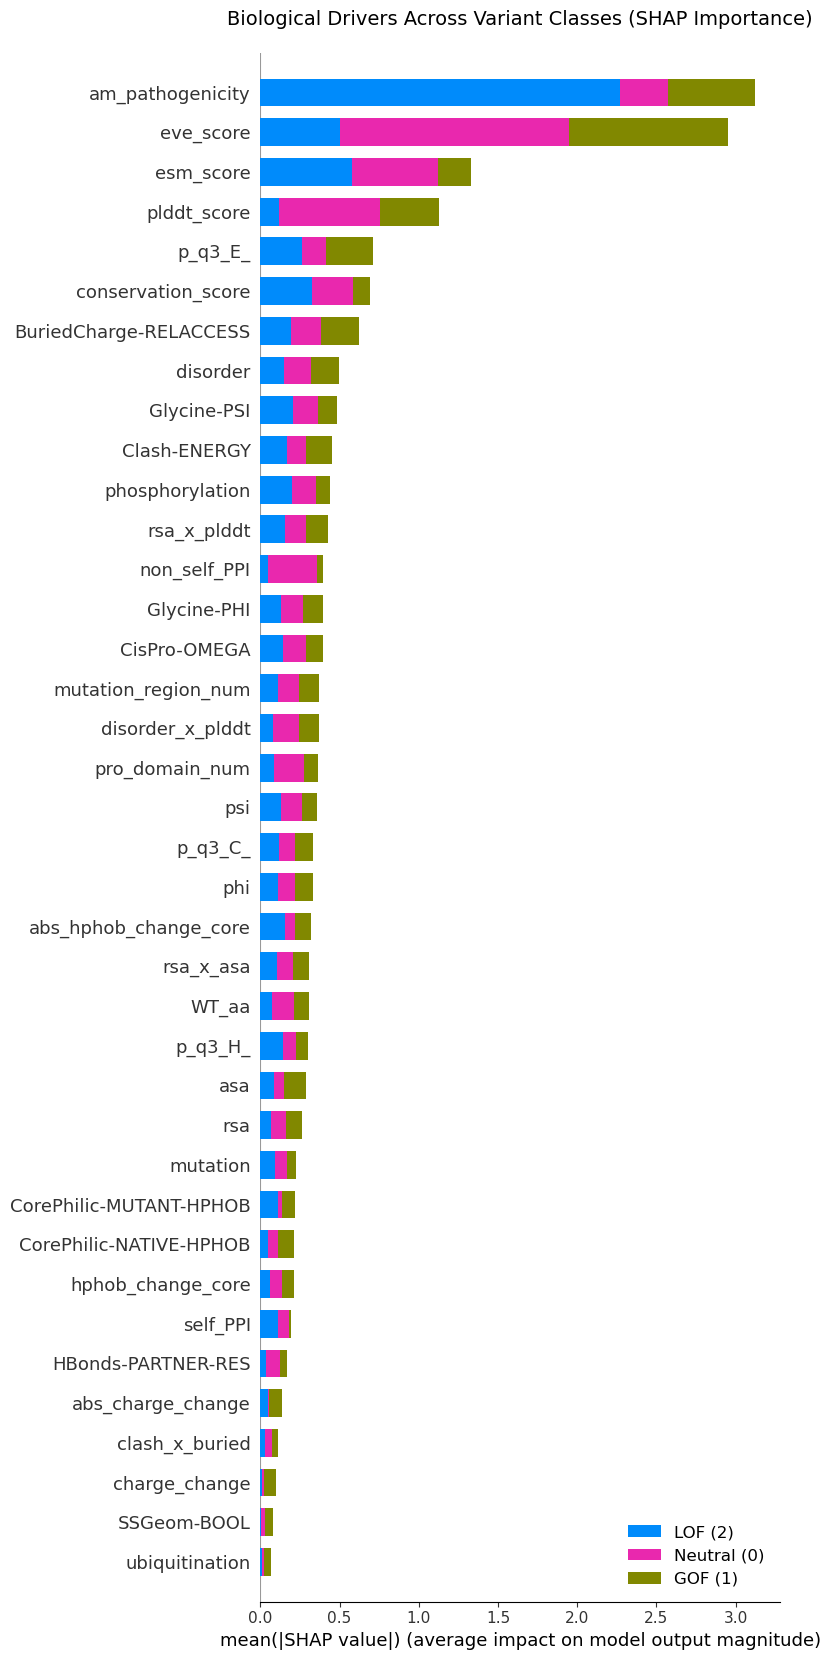

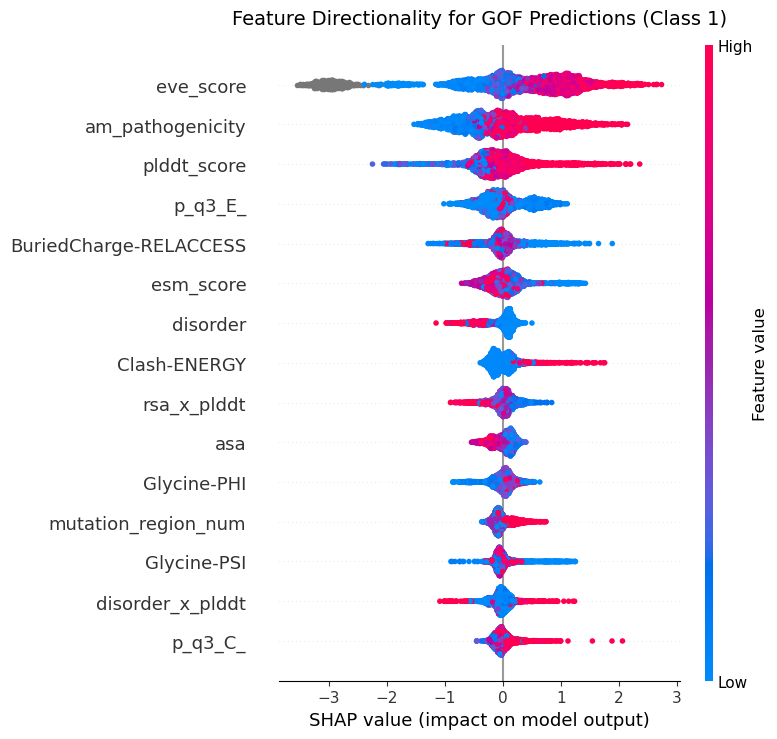

In [21]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import shap

print("Cracking open the LightGBM model with SHAP...")

# 1. Define class names matching your label order [0, 1, 2]
# Adjust these strings to match your encoding (e.g., [0: Neutral, 1: GOF, 2: LOF])
class_names = ["Neutral (0)", "GOF (1)", "LOF (2)"]

# 2. Fit LightGBM multiclass model
shap_model = lgb.LGBMClassifier(
    **best_params, random_state=42, verbose=-1, class_weight="balanced"
)
shap_model.fit(X_train_selected, Y_train)

# 3. Calculate SHAP values
explainer = shap.TreeExplainer(shap_model)
shap_values = explainer.shap_values(X_train_selected)

# 4. Plot Multiclass Bar Summary
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values,
    X_train_selected,
    class_names=class_names,
    max_display=38,
    plot_type="bar",
    show=False,
)
plt.title(
    "Biological Drivers Across Variant Classes (SHAP Importance)",
    fontsize=14,
    pad=20,
)
plt.tight_layout()
plt.show()

# Select index for GOF (adjust index if GOF is 0 or 2 in your model)
gof_idx = 1  

plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values[gof_idx] if isinstance(shap_values, list) else shap_values[:, :, gof_idx],
    X_train_selected,
    max_display=15,
    show=False
)
plt.title("Feature Directionality for GOF Predictions (Class 1)", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

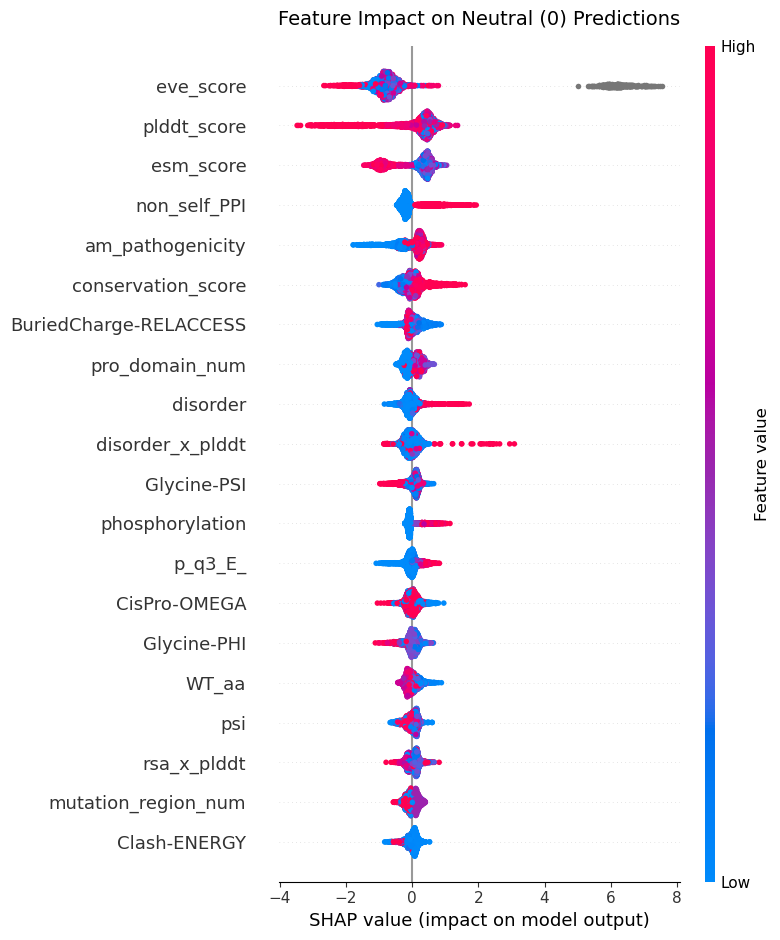

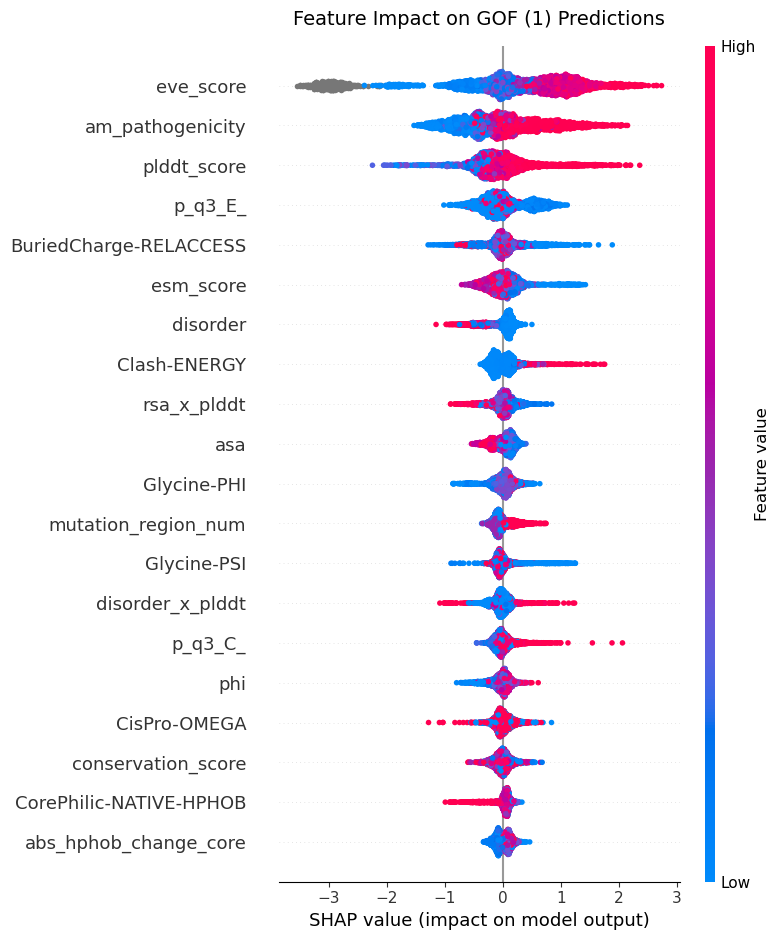

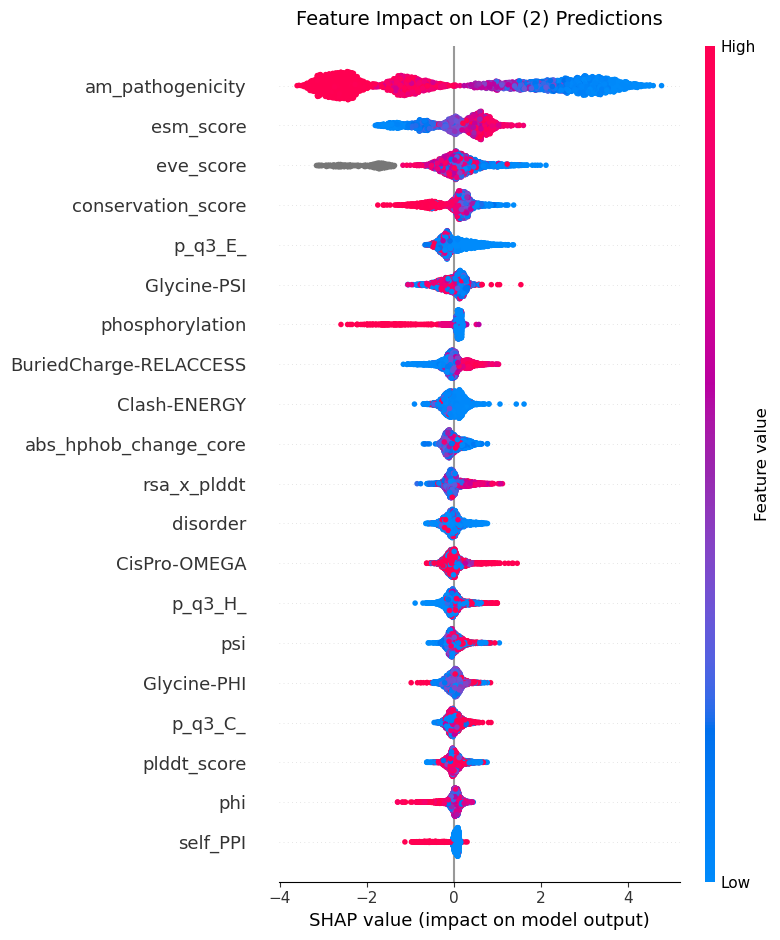

In [19]:
# Loop through each class and generate a directionality beeswarm plot
for class_idx, class_name in enumerate(class_names):
    plt.figure(figsize=(10, 6))

    # Slice SHAP values for the specific class
    class_shap_values = (
        shap_values[class_idx]
        if isinstance(shap_values, list)
        else shap_values[:, :, class_idx]
    )

    shap.summary_plot(
        class_shap_values,
        X_train_selected,
        max_display=20,
        show=False,
    )

    plt.title(f"Feature Impact on {class_name} Predictions", fontsize=14, pad=15)
    plt.tight_layout()
    plt.show()

> Predicting BenchMark data using 3 models:

In [ ]:
benchmark_multiclass = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/MachineLearning/LoGoFunc_benchmarking/Step-1_Data extraction/merged_logofunc_validation.csv")


# 3 . Load validation datasets
gof_val = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/gof_val_325.csv", index_col=0) # eve_score nan 21%
## gof_val['eve_score'].fillna(gof_val['eve_score'].mean(), inplace=True)
lof_val = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/lof_val_325.csv", index_col=0) # eve_score nan 8%
neutral_val = pd.read_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/EDA/neutral_val_550.csv", index_col=0) # eve_score nan 0%
##lof_val['eve_score'].fillna(lof_val['eve_score'].mean(), inplace=True)
# 4 . Combine validation datasets
test_val_df = pd.concat([gof_val, lof_val, neutral_val], ignore_index=True)

# 5. drop col [ 'Glycine-NATIVE-THRESHOLD', 'Glycine-MUTANT-THRESHOLD', 'Proline-MUTANT-THRESHOLD', 'Proline-NATIVE-THRESHOLD']
cols_drop = ['Glycine-NATIVE-THRESHOLD', 'Glycine-MUTANT-THRESHOLD', 'Proline-MUTANT-THRESHOLD', 'Proline-NATIVE-THRESHOLD', 'protein_len']
test_val_df.drop(columns=cols_drop, inplace=True)
# set new_hgnc_agg_ids as index for all three dataframes
test_val_df.set_index('new_hgnc_agg_ids', inplace=True)
test_val_df_cleaned = clean_cols(test_val_df)
test_val_df_cleaned = feature_engineering(test_val_df_cleaned)
# save the cleaned and engineered validation dataset to a CSV file
test_val_df_cleaned.to_csv("/Users/bh358AA/Desktop/chapter_2(GOF-LOF analysis)_January/Step-Last_MachineLearning/MachineLearning/LoGoFunc_benchmarking/Step-1_Data extraction/cleaned_test_val_df.csv", index=True)


In [28]:
# Step 1: predict test_val_df_cleaned using the calibrated LightGBM, XGB, and Random Forest models
# predict probabilities for the test_val_df_cleaned using the calibrated LightGBM model, drop 'goflof' and use features from lgb_features 45
test_val_df_cleaned_lgb = test_val_df_cleaned[lgb_features]
proba_val_cal_lgb = calibrated_model_lgb.predict_proba(test_val_df_cleaned_lgb)
# add predicted class based on argmax of probabilities
test_val_df_cleaned_lgb['predicted_class_lgb'] = np.argmax(proba_val_cal_lgb, axis=1)
# add predicted probabilities for each class
for i, cls in enumerate(CLASSES):
    test_val_df_cleaned_lgb[f'proba_{cls}_lgb'] = proba_val_cal_lgb[:, i]   
# save the predictions to a CSV file
test_val_df_cleaned_lgb.to_csv("test_val_df_cleaned_lgb_predictions_multi_class_allfeatures.csv", index=True)

# Step 2: predict test_val_df_cleaned using the calibrated XGB model
test_val_df_cleaned_xgb = test_val_df_cleaned[xgb_features]
proba_val_cal_xgb = calibrated_model_xgb.predict_proba(test_val_df_cleaned_xgb)
# add predicted class based on argmax of probabilities
test_val_df_cleaned_xgb['predicted_class_xgb'] = np.argmax(proba_val_cal_xgb, axis=1)
# add predicted probabilities for each class
for i, cls in enumerate(CLASSES):
    test_val_df_cleaned_xgb[f'proba_{cls}_xgb'] = proba_val_cal_xgb[:, i]
# save the predictions to a CSV file
test_val_df_cleaned_xgb.to_csv("test_val_df_cleaned_xgb_predictions_multi_class_allfeatures.csv", index=True)

# Step 3: predict test_val_df_cleaned using the calibrated Random Forest model
test_val_df_cleaned_rf = test_val_df_cleaned[rf_features]
proba_val_cal_rf = calibrated_model_rf.predict_proba(test_val_df_cleaned_rf)
# add predicted class based on argmax of probabilities
test_val_df_cleaned_rf['predicted_class_rf'] = np.argmax(proba_val_cal_rf, axis=1)
# add predicted probabilities for each class
for i, cls in enumerate(CLASSES):
    test_val_df_cleaned_rf[f'proba_{cls}_rf'] = proba_val_cal_rf[:, i]
# save the predictions to a CSV file
test_val_df_cleaned_rf.to_csv("test_val_df_cleaned_rf_predictions_multi_class_allfeatures.csv", index=True)

/var/folders/h0/49pf4hv97sdg37fww258kmrc0000gq/T/ipykernel_69935/448497438.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_val_df_cleaned_lgb['predicted_class_lgb'] = np.argmax(proba_val_cal_lgb, axis=1)
/var/folders/h0/49pf4hv97sdg37fww258kmrc0000gq/T/ipykernel_69935/448497438.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  test_val_df_cleaned_lgb[f'proba_{cls}_lgb'] = proba_val_cal_lgb[:, i]
/var/folders/h0/49pf4hv97sdg37fww258kmrc0000gq/T/ipykernel_69935/448497438.py:9: SettingWithCopyWarnin